# OEAS 805 Homework 3: Machine Learning - Regression of Surface Water Quality Variables in the Upper Chesapeake Bay
### Jupyter Notebook created by Nick Carpenter for the Fall 2026 OEAS 805: Advanced Environmental Data Science course

This notebook applies and compares three machine learning regression techniques (**polynomial regression**, **k-nearest neighbors (KNN)**, and **Radius Neighbors regression**) to predict the **diffuse light attenuation coefficient (Light Attenuation, `KD`, m⁻¹)**, a measure of water clarity, from three other surface water quality variables. Each technique is applied separately to each of the three input (predictor) variables (3 techniques x 3 inputs = 9 regressions), so the strength and shape (linear or non-linear) of each relationship can be compared.

The data are surface-water (0.5 m) measurements from the Chesapeake Bay Program Tidal Water Quality Monitoring (TWQM) program at **station CB4.1C** in the upper mainstem Chesapeake Bay, collected between October 2021 and November 2025 (Chesapeake Bay Program, 2026). Variable names, descriptions, and units come from the [DataHub parameter lookup tables](https://datahub.chesapeakebay.net/Home/Documentation) (Chesapeake Bay Program, 2026). The notebook is organized as follows:

1. Data Loading, Cleaning, and Reshaping
2. Target Variable Selection and Input (Predictor) Variable Selection
3. Train/Test Split
4. Model Implementation (including automatic hyperparameter tuning)
5. Hyperparameter Explanation
6. Model Evaluation & Visualization
7. Overall Conclusions

The notebook runs from start to finish without user input: the best hyperparameters for the polynomial regression, KNN, and Radius Neighbors models are selected automatically by cross-validation.

## Bibliography

Chesapeake Bay Program. (2026). *Chesapeake Bay Program DataHub: Water quality data and documentation*. https://datahub.chesapeakebay.net/Home/Documentation

Correll, D. L. (1998). The role of phosphorus in the eutrophication of receiving waters: A review. *Journal of Environmental Quality, 27*(2), 261-266. https://doi.org/10.2134/jeq1998.00472425002700020004x

Dennison, W. C., Orth, R. J., Moore, K. A., Stevenson, J. C., Carter, V., Kollar, S., Bergstrom, P. W., & Batiuk, R. A. (1993). Assessing water quality with submersed aquatic vegetation. *BioScience, 43*(2), 86-94.

Gallegos, C. L. (2001). Calculating optical water quality targets to restore and protect submersed aquatic vegetation: Overcoming problems in partitioning the diffuse attenuation coefficient for photosynthetically active radiation. *Estuaries, 24*(3), 381-397.

Hastie, T., Tibshirani, R., & Friedman, J. (2009). *The elements of statistical learning: Data mining, inference, and prediction* (2nd ed.). Springer.

Kemp, W. M., Boynton, W. R., Adolf, J. E., Boesch, D. F., Boicourt, W. C., Brush, G., Cornwell, J. C., Fisher, T. R., Glibert, P. M., Hagy, J. D., Harding, L. W., Houde, E. D., Kimmel, D. G., Miller, W. D., Newell, R. I. E., Roman, M. R., Smith, E. M., & Stevenson, J. C. (2005). Eutrophication of Chesapeake Bay: Historical trends and ecological interactions. *Marine Ecology Progress Series, 303*, 1-29. https://doi.org/10.3354/meps303001

Kirk, J. T. O. (2011). *Light and photosynthesis in aquatic ecosystems* (3rd ed.). Cambridge University Press.

Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825-2830.

Preisendorfer, R. W. (1986). Secchi disk science: Visual optics of natural waters. *Limnology and Oceanography, 31*(5), 909-926.

Roberts, D. R., Bahn, V., Ciuti, S., Boyce, M. S., Elith, J., Guillera-Arroita, G., Hauenstein, S., Lahoz-Monfort, J. J., Schröder, B., Thuiller, W., Warton, D. I., Wintle, B. A., Hartig, F., & Dormann, C. F. (2017). Cross-validation strategies for data with temporal, spatial, hierarchical, or phylogenetic structure. *Ecography, 40*(8), 913-929. https://doi.org/10.1111/ecog.02881

Schubel, J. R., & Pritchard, D. W. (1986). Responses of upper Chesapeake Bay to variations in discharge of the Susquehanna River. *Estuaries, 9*(4A), 236-249.

scikit-learn developers. (2026). *sklearn.neighbors.RadiusNeighborsRegressor*. In *scikit-learn documentation*. https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.RadiusNeighborsRegressor.html

Talley, L. D., Pickard, G. L., Emery, W. J., & Swift, J. H. (2011). *Descriptive physical oceanography: An introduction* (6th ed.). Academic Press.

In [1]:
# Load ALL of the packages you will need for the entire notebook (no imports appear later on)

import os          # used to build file paths that work on any operating system
import warnings    # used to silence repetitive (harmless) convergence warnings during hyperparameter searches

# numpy is a package for numerical arrays and math
import numpy as np

# pandas is a package for data analysis and manipulation
import pandas as pd

# IPython's display function lets a loop show several tables in one code cell
from IPython.display import display

# seaborn is a data visualization package
import seaborn as sns

# matplotlib is the OG python plotting library, useful for customizing plots
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D   # used to build custom legend handles

# scipy.stats provides statistical functions (here: Pearson correlation)
from scipy import stats

# scikit-learn is the machine learning package used for all of the regression models
from sklearn.model_selection import train_test_split, GridSearchCV, RepeatedKFold, cross_val_score
from sklearn.pipeline import Pipeline                  # chains scaling + model into one object
from sklearn.preprocessing import StandardScaler       # rescales each input to mean 0, std 1
from sklearn.linear_model import LinearRegression     # Model 1
from sklearn.neighbors import KNeighborsRegressor     # Model 2
from sklearn.neighbors import RadiusNeighborsRegressor  # Model 3
from sklearn.preprocessing import PolynomialFeatures    # used to check whether a curved (non-linear) fit is better than a line
from sklearn.dummy import DummyRegressor              # a 'no-skill' baseline model that always predicts the training mean
from sklearn.base import clone                        # makes an unfitted copy of a model with the same hyperparameters
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# Make the tables a little easier to read
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)

--------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------

## 01) Data Loading, Cleaning, and Reshaping

The surface-water dataset is in **"long" format**: every row is a single measurement of a single variable (`Parameter`) on a single date, with the value in `MeasureValue` and units in `MeasureUnit`. This section loads the data and the metadata lookup table, builds the label/unit/color settings used for all of the plots, and reshapes the data into **"wide" format** (one row per sampling date, one column per variable), so each row is one water sample described by a set of variables. Cleaning steps that apply only to the variables used in the regression analysis are done at the start of Section 02.

--------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------

### 01.1 Loading the Data

Read in the .csv file and take a first look at its size, data types, and what does (and does not) vary across the dataset.

In [2]:
# load the .csv file with the Chesapeake Bay water quality data

# This assumes the notebook lives in HW3_CODE and the data lives in a sibling folder HW3_DATA
# (os.path.join builds the path correctly on Windows, Mac, and Linux; '..' means "go up one folder")
data_dir    = os.path.join('..', 'HW3_DATA')
infile      = os.path.join(data_dir, 'CBP_TWQM_MAIN_WQ_2021_2026_surface.csv')
lookup_file = os.path.join(data_dir, 'DataHub_WaterQuality_LookupTables.xlsx')

# Read in the .csv file
data = pd.read_csv(infile)
# show the data head (basically, a quick preview of the data in table format that truncates the number of entries)
data.head()

,Station,FieldActivityId,Cruise,Program,Project,DataCollector,DataProvider,Latitude,Longitude,SampleDate,SampleTime,TotalDepthM,UpperPycnoclineDepthM,LowerPycnoclineDepthM,SampleDepthM,Layer,SampleType,SampleReplicate,Parameter,Qualifier,MeasureValue,MeasureUnit,Method,Lab,Problem,PrecisionPC,BiasPC,Details,TierLevel
0,CB4.1C,785801,BAY900,TWQM,MAIN,MDDNR,MDDNR,38.82593,-76.39945,2025-11-18,15:00:00,30.8,NaN,NaN,0.5,S,D,S1,CHLA,NaN,11.000,UG/L,L01,CBL,NaN,NaN,NaN,NaN,T3
1,CB4.1C,785781,BAY898,TWQM,MAIN,MDDNR,MDDNR,38.82593,-76.39945,2025-10-06,12:29:00,31.0,8.5,14.5,0.5,S,D,S1,CHLA,NaN,7.049,UG/L,L01,CBL,NaN,NaN,NaN,NaN,T3
2,CB4.1C,785724,BAY895,TWQM,MAIN,MDDNR,MDDNR,38.82593,-76.39945,2025-08-26,12:27:00,30.4,10.5,19.5,0.5,S,D,S1,CHLA,NaN,7.156,UG/L,L01,CBL,NaN,NaN,NaN,NaN,T3
3,CB4.1C,785723,BAY894,TWQM,MAIN,MDDNR,MDDNR,38.82593,-76.39945,2025-08-06,12:20:00,30.8,4.5,13.5,0.5,S,D,S1,CHLA,NaN,15.620,UG/L,L01,CBL,NaN,NaN,NaN,NaN,T3
4,CB4.1C,785680,BAY893,TWQM,MAIN,MDDNR,MDDNR,38.82593,-76.39945,2025-07-21,12:50:00,31.5,3.5,9.5,0.5,S,D,S1,CHLA,NaN,38.662,UG/L,L01,CBL,NaN,NaN,NaN,NaN,T3


In [3]:
# The shape of the data
# (nrows, ncols)
print("(# rows, # columns):")
print(data.shape)

# Print information about the data in the dataframe, including the dtype of each column
print("\nData types and non-null counts per column of the dataframe:")
data.info()

(# rows, # columns):
(1223, 29)

Data types and non-null counts per column of the dataframe:
<class 'pandas.DataFrame'>
RangeIndex: 1223 entries, 0 to 1222
Data columns (total 29 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Station                1223 non-null   str    
 1   FieldActivityId        1223 non-null   int64  
 2   Cruise                 1223 non-null   str    
 3   Program                1223 non-null   str    
 4   Project                1223 non-null   str    
 5   DataCollector          1223 non-null   str    
 6   DataProvider           1223 non-null   str    
 7   Latitude               1223 non-null   float64
 8   Longitude              1223 non-null   float64
 9   SampleDate             1223 non-null   str    
 10  SampleTime             1223 non-null   str    
 11  TotalDepthM            1223 non-null   float64
 12  UpperPycnoclineDepthM  1022 non-null   float64
 13  LowerPycnoclineDepthM  102

In [4]:
# Convert the 'SampleDate' column from text into a proper datetime type
data['SampleDate'] = pd.to_datetime(data['SampleDate'])

# Check what is (and is not) varying in this dataset
print("Station(s):", data['Station'].unique())
print("Layer(s):", data['Layer'].unique())
print("Sample depth(s) in m:", data['SampleDepthM'].unique())
print("Date range:", data['SampleDate'].min().date(), "to", data['SampleDate'].max().date())
print("Number of unique sampling dates:", data['SampleDate'].nunique())

Station(s): <ArrowStringArray>
['CB4.1C']
Length: 1, dtype: str
Layer(s): <ArrowStringArray>
['S']
Length: 1, dtype: str
Sample depth(s) in m: [0.5 0. ]
Date range: 2021-10-05 to 2025-11-18
Number of unique sampling dates: 42


### 01.2 Variable Metadata, Plot Labels, and Colors

Use the DataHub lookup table to translate the short `Parameter` codes into descriptive names, and set up the label, unit, and color settings that every plot in this notebook will use.

In [5]:
# Summary of every variable ("Parameter") in the dataset:
# how many measurements, and basic stats, with the units reported in the data
print("Summary of each Parameter in the long-format data:")
param_summary = (data.groupby(['Parameter', 'MeasureUnit'])['MeasureValue']
                     .agg(['count', 'mean', 'min', 'max']).round(3))
param_summary

Summary of each Parameter in the long-format data:


,,count,mean,min,max
Parameter,MeasureUnit,,,,
CHLA,UG/L,42,13.866,3.524,38.662
DIN,MG/L,60,0.141,0.006,0.646
DO,MG/L,42,9.538,5.900,14.400
DON,MG/L,60,0.273,0.204,0.352
DOP,MG/L,70,0.006,0.001,0.024
KD,1/M,42,0.792,0.000,1.505
NH4F,MG/L,42,0.016,0.009,0.053
NO23F,MG/L,42,0.158,0.001,0.634
NO2F,MG/L,42,0.006,0.001,0.031


In [6]:
# The DataHub lookup table translates the short Parameter codes into descriptions.
# Read the 'Parameter' sheet from the metadata excel file (drop_duplicates because a few codes are listed twice)
param_lookup = pd.read_excel(lookup_file, sheet_name='Parameter').drop_duplicates(subset='Parameter')

# Keep only the parameters that are present in our dataset
in_data = param_lookup[param_lookup['Parameter'].isin(data['Parameter'].unique())]
print("Names and descriptions of the Parameters in this dataset (from the DataHub lookup table):")
in_data[['Parameter', 'ParameterAlternateName', 'ParameterDescription']].reset_index(drop=True)

Names and descriptions of the Parameters in this dataset (from the DataHub lookup table):


,Parameter,ParameterAlternateName,ParameterDescription
0,CHLA,Chlorophyll-A,Active Chlorophyll-A
1,DIN,Dissolved Inorganic Nitrogen,Dissolved Inorganic Nitrogen
2,DO,Dissolved Oxygen,Dissolved Oxygen In MG/L
3,DON,Dissolved Organic Nitrogen,Dissolved Organic Nitrogen
4,DOP,Dissolved Organic Phosphorus,Dissolved Organic Phosphorus
5,KD,Light Attenuation,Light Attenuation
6,NH4F,Ammonium Nitrogen As N (Filtered),Ammonium Nitrogen As N (Filtered Sample)
7,NO23F,Nitrite+Nitrate Nitrogen As N (Filtered),Nitrite+Nitrate Nitrogen As N (Filtered Sample)
8,NO2F,Nitrite Nitrogen As N (Filtered),Nitrite Nitrogen As N (Filtered Sample)
9,NO3F,Nitrate Nitrogen As N (Filtered),Nitrate Nitrogen As N (Filtered Sample)


In [7]:
# ---- Plot labels ----
# All plot labels use the 'ParameterAlternateName' from the lookup table followed by the units in parentheses.
alt_name = dict(zip(param_lookup['Parameter'], param_lookup['ParameterAlternateName']))

# Units as reported in the data (e.g., 'UG/L'), and a dictionary converting them to proper notation
# (Greek letters, superscripts)
raw_units = data.groupby('Parameter')['MeasureUnit'].first().to_dict()
unit_pretty = {'UG/L': 'μg/L', 'MG/L': 'mg/L', '1/M': 'm⁻¹', 'M': 'm', 'PPT': 'ppt',
               'DEG C': '°C', 'UMHOS/CM': 'μmho/cm', 'SU': '', 'NONE': ''}
# SIGMA_T is listed with units 'NONE' in the data, but it is the water density minus 1000 kg/m³
unit_override = {'SIGMA_T': 'kg/m³ − 1000'}

def get_units(code):
    # returns the nicely formatted units of a Parameter code
    if code in unit_override:
        return unit_override[code]
    return unit_pretty.get(raw_units.get(code, ''), raw_units.get(code, ''))

def axis_label(code):
    # returns 'ParameterAlternateName (units)', e.g. 'Chlorophyll-A (μg/L)'
    units = get_units(code)
    return f"{alt_name[code]} ({units})" if units else alt_name[code]

# ---- Plot colors ----
var_colors = {'KD': '#555555',        # target variable (dark gray)
              'CHLA': '#267207',      # input 1 (green)
              'SIGMA_T': '#015f63',   # input 2 (teal)
              'PP': '#998703'}        # input 3 (gold)
other_color = '#9e9e9e'               # other candidate variables that are not selected as inputs (light gray)

# one color per model, used when the three techniques are compared in the same plot
model_colors = {'Polynomial Regression': '#222222', 'KNN': '#d1495b', 'Radius Neighbors': '#6a3d9a'}

print("Example plot labels for the variables used in this notebook:")
for code in ['KD', 'CHLA', 'SIGMA_T', 'PP', 'TSS']:
    print(f"  {code:8s} -> {axis_label(code)}")

Example plot labels for the variables used in this notebook:
  KD       -> Light Attenuation (m⁻¹)
  CHLA     -> Chlorophyll-A (μg/L)
  SIGMA_T  -> Water Density (kg/m³ − 1000)
  PP       -> Particulate Phosphorus (mg/L)
  TSS      -> Total Suspended Solids (mg/L)


### 01.3 Reshaping from Long to Wide Format

`pivot_table` turns each `Parameter` into its own column, with one row per `SampleDate`. If a date has more than one value for the same parameter (e.g., laboratory replicates), they are averaged.

In [8]:
# Check how many measurements each Parameter has per sampling date.
# A max of 1 means no replicates for that variable.
counts_per_date = data.groupby(['Parameter', 'SampleDate']).size().groupby('Parameter').max()
print("Variables with replicate measurements on the same date (max # per date > 1):")
print(counts_per_date[counts_per_date > 1].to_dict())

Variables with replicate measurements on the same date (max # per date > 1):
{'DIN': 2, 'DON': 2, 'DOP': 2, 'NO3F': 2, 'TON': 2}


In [9]:
# Pivot from long to wide format: one row per sampling date, one column per Parameter
wide = data.pivot_table(index='SampleDate', columns='Parameter', values='MeasureValue', aggfunc='mean')
wide.columns.name = None   # drops the leftover 'Parameter' label from the column index

print("Wide-format shape (# sampling dates, # variables):", wide.shape)
wide.head()

Wide-format shape (# sampling dates, # variables): (42, 27)


,CHLA,DIN,DO,DON,DOP,KD,NH4F,NO23F,NO2F,NO3F,PC,PH,PHEO,PN,PO4F,PP,SALINITY,SECCHI,SIGMA_T,SPCOND,TDN,TDP,TN,TON,TP,TSS,WTEMP
SampleDate,,,,,,,,,,,,,,,,,,,,,,,,,,,
2021-10-05,7.595,0.270,7.3,0.260,0.00940,0.9170,0.016,0.254,0.0309,0.2231,1.050,8.1,6.859,0.217,0.0037,0.0215,8.31,1.4,3.82561,14700.0,0.53,0.0131,0.747,0.477,0.0346,3.8,23.3
2021-11-17,17.444,0.444,10.4,0.286,0.02370,1.0270,0.009,0.435,0.0036,0.4314,1.060,8.1,2.492,0.192,0.0034,0.0215,9.33,1.6,6.71673,16300.0,0.73,0.0271,0.922,0.478,0.0486,6.8,12.8
2021-12-08,12.935,0.332,10.2,0.228,0.00705,0.7500,0.032,0.300,0.0095,0.2905,0.948,7.9,3.097,0.176,0.0034,0.0186,11.87,1.6,9.15105,20200.0,0.56,0.0096,0.736,0.404,0.0282,7.2,9.2
2022-03-15,20.292,0.482,11.9,0.278,0.00355,0.0000,0.010,0.472,0.0039,0.4681,1.930,8.0,1.239,0.312,0.0034,0.0182,9.33,1.2,7.38314,16300.0,0.76,0.0061,1.072,0.590,0.0243,4.8,6.6
2022-04-12,29.904,0.422,11.4,0.328,0.00460,1.0714,0.021,0.401,0.0059,0.3951,2.080,8.2,2.350,0.354,0.0042,0.0269,8.50,1.0,6.39514,15000.0,0.75,0.0088,1.104,0.682,0.0357,10.0,10.3


In [10]:
# Missing data check: number of missing (NaN) values in the wide-format dataset
print("Total # of missing (NaN) values in the wide-format data:", int(wide.isna().sum().sum()))
print("Variables with any missing values:", wide.columns[wide.isna().any()].tolist())

Total # of missing (NaN) values in the wide-format data: 0
Variables with any missing values: []


--------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------

### SECTION 01 SUMMARY: Dataset Overview and Setup

**Findings of this section:**
- The dataset (Chesapeake Bay Program, 2026) has 1,223 measurements of **27 variables** at a single station (CB4.1C) and a single depth (0.5 m, surface layer) on **42 sampling dates** between October 2021 and November 2025, so no station or depth variable needs to be handled.
- After pivoting from long to wide format, there is one row per sampling date and one column per variable (42 rows x 27 columns) with **no missing values**. The only variables with multiple values on a single date are a few nutrient species (`DIN`, `DON`, `DOP`, `NO3F`, `TON`), which were averaged (and are not used as inputs).
- The DataHub lookup table gives each variable a descriptive name (`ParameterAlternateName`), which is used in all plot labels together with the units. The units were converted to proper notation (e.g., μg/L, m⁻¹). Note that the parameter code in this dataset is `CHLA` (Chlorophyll-A); the lookup table also has a separate `CHL_A` entry (Chlorophyll A) that does not appear in this data.
- The plot colors for the target and the three chosen inputs are set up once (Chlorophyll-A `#267207`, Water Density `#015f63`, Particulate Phosphorus `#998703`) so they are used consistently throughout the notebook.
- The small number of samples (42 dates) is the biggest constraint on this analysis, and it shrinks further after the target-specific cleaning in Section 02.

--------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------

--------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------

## 02) Target Variable Selection and Input (Predictor) Variable Selection

**Target variable: Light Attenuation (`KD`, m⁻¹).** `KD` is the diffuse attenuation coefficient for downwelling light: light intensity decays approximately exponentially with depth at a rate set by `KD`, so a larger `KD` means murkier water (Kirk, 2011). It is chosen as the target variable for three reasons:
1. **It is a high-level, integrative water quality indicator.** `KD` summarizes the combined effect of everything in the water that absorbs or scatters light: the water itself, phytoplankton, suspended particles, and dissolved colored organic matter (Gallegos, 2001; Kirk, 2011). Water clarity is a central management metric in the Chesapeake Bay because the light reaching the bottom determines whether submerged aquatic vegetation (SAV) can survive, and SAV habitat requirements have been expressed in terms of water quality variables that include `KD`, chlorophyll-a, and suspended solids (Dennison et al., 1993).
2. **The dataset contains measured variables for the main light-attenuating components.** Chlorophyll-a represents phytoplankton, suspended solids and particulate nutrients represent particles, and water density represents the water mass (fresh river water vs. saltier Bay water). A regression of `KD` on these variables is therefore physically meaningful.
3. **It is practical for regression.** There is one `KD` value per sampling date, and (as shown later in this section) its distribution is roughly bell-shaped. Light profile measurements can also fail (five failed `KD` values are shown below), so estimating `KD` from routine water samples could help fill these gaps.


**Selecting the inputs.** The inputs are selected in a data-driven way. The section first prepares and cleans the variables of interest (02.1), then compares `KD` with a broad set of candidate variables using a correlation matrix (02.2) and scatter plots (02.3), and finally describes the three chosen inputs (02.4). Each input will be used in its own separate regression (the inputs are **not** combined into one multi-variable model), so only the relationship between `KD` and each individual variable matters.

**Candidate inputs:** `CHLA` (chlorophyll-a, a proxy for phytoplankton biomass), `SIGMA_T` (water density, which is calculated from salinity and temperature and describes the water mass/stratification), and `TSS` (total suspended solids, i.e., sediment and particles). Particulate Phosphorus (`PP`) is added as a possible replacement for `TSS` if the relationship is not as evident in this dataset. Light in water is absorbed and scattered by phytoplankton, suspended particles, and dissolved material, so these are physically sensible drivers of `KD`.

The following cells explore the variables to check whether these choices are supported by the data.

--------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------

### 02.1 Cleaning and Quality Checks for the Variables of Interest

Check the data quality flags and missing values for the target and the candidate input variables, and deal with a problem found in the target variable (`KD`).

In [11]:
# Target variable and a list of candidate input variables that will be examined in this section
target = 'KD'
candidates = ['CHLA', 'SIGMA_T', 'PP', 'TSS', 'TP', 'PC', 'PN', 'SECCHI', 'SALINITY', 'WTEMP', 'PHEO']
focus = [target] + candidates

# Check the data quality flags for these variables:
# 'Qualifier' (e.g., '<' = below the detection limit) and 'Problem' (a problem code for that measurement)
sub_data = data[data['Parameter'].isin(focus)]
flag_counts = (sub_data.assign(Qualifier_flagged=sub_data['Qualifier'].notna(),
                               Problem_flagged=sub_data['Problem'].notna())
                       .groupby('Parameter')[['Qualifier_flagged', 'Problem_flagged']].sum().astype(int)
                       .reindex(focus))
print("Number of flagged measurements for the target and candidate variables:")
flag_counts

Number of flagged measurements for the target and candidate variables:


,Qualifier_flagged,Problem_flagged
Parameter,,
KD,0,0
CHLA,0,0
SIGMA_T,0,0
PP,0,0
TSS,0,0
TP,0,0
PC,0,1
PN,0,1
SECCHI,0,0


In [12]:
# Which measurements were flagged, and what do the flag codes mean (from the lookup table)?
flagged = sub_data[sub_data['Qualifier'].notna() | sub_data['Problem'].notna()]
print("Flagged measurements:")
print(flagged[['SampleDate', 'Parameter', 'MeasureValue', 'Qualifier', 'Problem']].to_string(index=False))

print("\nMeaning of the 'Problem' codes found:")
problem_lookup = pd.read_excel(lookup_file, sheet_name='Problem')
print(problem_lookup[problem_lookup['Problem'].isin(flagged['Problem'].dropna().unique())].to_string(index=False))

print("\nTotal # of missing (NaN) values per column (target + candidates):")
print(wide[focus].isna().sum().to_dict())

Flagged measurements:
SampleDate Parameter  MeasureValue Qualifier Problem
2023-03-16        PC         1.130       NaN      JJ
2025-04-15      PHEO         0.740         <     NaN
2024-06-04      PHEO         0.740         <     NaN
2023-03-16        PN         0.192       NaN      JJ

Meaning of the 'Problem' codes found:
Problem                     ProblemDescription
     JJ Volume Filtered Not Recorded (Assumed)

Total # of missing (NaN) values per column (target + candidates):
{'KD': 0, 'CHLA': 0, 'SIGMA_T': 0, 'PP': 0, 'TSS': 0, 'TP': 0, 'PC': 0, 'PN': 0, 'SECCHI': 0, 'SALINITY': 0, 'WTEMP': 0, 'PHEO': 0}


--------------------------------------------------------------------------------------

None of the measurements of `KD`, `CHLA`, `SIGMA_T`, `PP`, `TSS`, `TP`, `SECCHI`, `SALINITY`, or `WTEMP` carry a data quality flag, and there are no missing values. The only flagged measurements are for secondary candidates: one `PC` and one `PN` value (both from 2023-03-16) flagged `JJ` ("Volume Filtered Not Recorded (Assumed)"), and two `PHEO` values reported as below the detection limit (`<`). None of these affect the three variables that end up being used as inputs, so no measurements need to be removed or imputed for quality-flag reasons.

--------------------------------------------------------------------------------------

#### A problem with `KD`: values of exactly zero
`KD` is a coefficient of light attenuation, so a value of exactly `0.0` means no light is lost at all with depth, which is not physically possible in the Chesapeake Bay. The following cells check for these values.

In [13]:
print("Descriptive statistics for Light Attenuation (KD):")
print(wide['KD'].describe().round(3))

print("\nSampling dates where KD == 0 (shown with other clarity-related variables):")
zero_kd = wide[wide['KD'] == 0][['KD', 'SECCHI', 'TSS', 'CHLA']]
zero_kd

Descriptive statistics for Light Attenuation (KD):
count    42.000
mean      0.792
std       0.356
min       0.000
25%       0.703
50%       0.878
75%       0.979
max       1.505
Name: KD, dtype: float64

Sampling dates where KD == 0 (shown with other clarity-related variables):


,KD,SECCHI,TSS,CHLA
SampleDate,,,,
2022-03-15,0.0,1.2,4.8,20.292
2022-05-17,0.0,1.4,9.2,37.380
2022-06-29,0.0,1.3,7.7,17.088
2022-08-09,0.0,1.2,10.0,10.894
2022-08-23,0.0,1.4,3.6,7.877


In [14]:
# Sanity check: KD and Secchi depth (how deep a white disk is visible) should be inversely related,
# with KD * Secchi depth roughly constant (commonly ~1 to 2).
valid = wide[wide['KD'] > 0]
print("KD x Secchi depth, valid (KD > 0) samples:")
print((valid['KD'] * valid['SECCHI']).describe().round(2))
print("\nSecchi depth on the KD == 0 dates (m):", zero_kd['SECCHI'].tolist())

KD x Secchi depth, valid (KD > 0) samples:
count    37.00
mean      1.24
std       0.28
min       0.56
25%       1.07
50%       1.26
75%       1.38
max       2.01
dtype: float64

Secchi depth on the KD == 0 dates (m): [1.2, 1.4, 1.3, 1.2, 1.4]


--------------------------------------------------------------------------------------

Five `KD` values are exactly `0.0`, all from sampling dates between March and August 2022. These are almost certainly not real measurements: water at this station is turbid enough that light has to be attenuated (Secchi depths of 1.2-1.4 m on those same days). In the valid data, `KD` × Secchi depth averages about 1.2, consistent with the well-established inverse relationship between Secchi depth and light attenuation (Preisendorfer, 1986), but a `KD` of zero would break that relationship entirely. These zeros are most likely failed or missing light-profile measurements for this time period stored as `0` rather than as a blank, similar to the zero-filled rows removed in HW2.

Leaving these values in would teach the models that some moderately turbid, high-chlorophyll samples have perfectly clear water, which is wrong and would heavily distort the fits. The 5 rows are removed, leaving **37 samples**.

--------------------------------------------------------------------------------------

In [15]:
# Remove the KD == 0 rows from the working dataset
print("Removing rows where KD == 0 (failed/placeholder measurements):")
n_before = len(wide)
wide = wide[wide['KD'] > 0].copy()
print(f"Rows before: {n_before}, rows after: {len(wide)}")

Removing rows where KD == 0 (failed/placeholder measurements):
Rows before: 42, rows after: 37


### 02.2 Correlation Matrix

Compare how strongly the target (`KD`) is correlated with the original candidate inputs (`CHLA`, `SIGMA_T`, `TSS`) and with other relevant variables, including Particulate Phosphorus (`PP`), before making the final input selection. (The correlation matrix uses the short `Parameter` codes as labels.)

In [16]:
# Pearson correlation of KD with every other variable in the dataset, sorted from strongest to weakest
kd_corr = wide.corr()['KD'].drop('KD')
kd_corr_table = pd.DataFrame({'Name': [alt_name[c] for c in kd_corr.index],
                              'Pearson r with KD': kd_corr.round(2)})
kd_corr_table = kd_corr_table.reindex(kd_corr.abs().sort_values(ascending=False).index)

print("The 12 variables most strongly correlated with KD (by absolute value of r):")
kd_corr_table.head(12)

The 12 variables most strongly correlated with KD (by absolute value of r):


,Name,Pearson r with KD
CHLA,Chlorophyll-A,0.70
PP,Particulate Phosphorus,0.69
TON,Total Organic Nitrogen,0.69
PN,Particulate Nitrogen,0.67
PC,Particulate Carbon,0.67
TP,Total Phosphorus,0.66
SECCHI,Secchi Depth,-0.60
SIGMA_T,Water Density,-0.58
SALINITY,Salinity,-0.49
SPCOND,Conductivity,-0.49


Heatmap: correlation matrix of KD and the candidate input variables


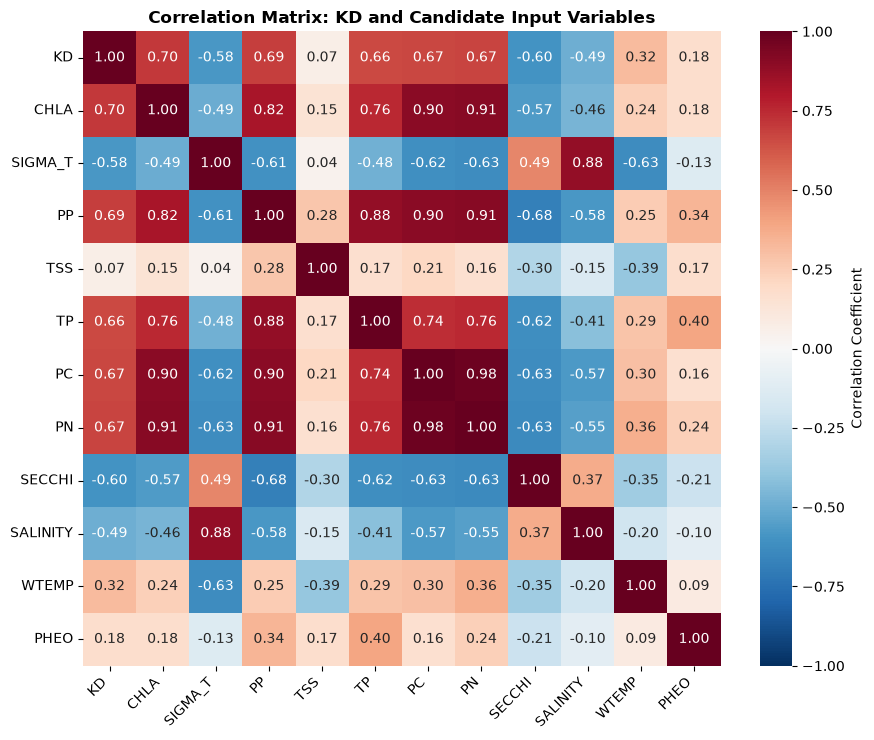

In [17]:
print("Heatmap: correlation matrix of KD and the candidate input variables")

# Candidates: the original choices (CHLA, SIGMA_T, TSS), Particulate Phosphorus (PP), and other relevant variables:
# TP/PC/PN (other particle-related nutrients), SECCHI (another measure of clarity),
# SALINITY/WTEMP (the ingredients of SIGMA_T), and PHEO (a chlorophyll degradation product)
corr_cols = ['KD', 'CHLA', 'SIGMA_T', 'PP', 'TSS', 'TP', 'PC', 'PN', 'SECCHI', 'SALINITY', 'WTEMP', 'PHEO']
corr_matrix = wide[corr_cols].corr()

fig, ax = plt.subplots(figsize=(9,7.5), dpi=100)
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, ax=ax,
            cbar_kws={'label': 'Correlation Coefficient'})
ax.set_title('Correlation Matrix: KD and Candidate Input Variables', fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

--------------------------------------------------------------------------------------

The correlation matrix (and the table of the 12 strongest correlations with `KD` above it) shows...
**Candidate Input Variables**:
- **Chlorophyll-A (`CHLA`) and Particulate Phosphorus (`PP`) have the strongest correlations with `KD`** (r = 0.70 and 0.69). A positive correlation is expected: more phytoplankton and more particles mean more light absorbed and scattered (Gallegos, 2001; Kirk, 2011).
- **Water Density (`SIGMA_T`) is moderately negatively correlated with `KD`** (r = -0.58): denser (saltier, colder) water tends to be clearer.
- **Total Suspended Solids (`TSS`) is essentially uncorrelated with `KD`** (r = 0.07), which is surprising for a variable that is expected to cause turbidity. It is also only weakly correlated with the other variables in the matrix (|r| of 0.39 or less). Physically, it should matter, but here a single high value (19.2 mg/L) and a lot of scatter dominate it. TSS measures total mass of particles in a water sample, while light attenuation also depends on particle size and composition, and on dissolved colored material (not measured in this dataset). Therefore, **Particulate Phosphorus (`PP`)** is used for the third variable instead.

Other variables/ relationships in the heatmap:
- **`PC`, `PN`, and `TP` correlate with `KD` about as well as `PP`** (r = 0.66 to 0.67), but `PC` and `PN` are almost perfectly correlated with `CHLA` (r = 0.90 and 0.91) and with each other (r = 0.98): they mostly measure the same thing (particulate organic matter, which in surface water is largely phytoplankton), so they add almost no new information beyond `CHLA` and `PP`. `TP` includes both dissolved and particulate phosphorus, and `PP` (the particulate part) is the fraction that can physically interact with light.
- **`SECCHI` (r = -0.60) is another measure of water clarity**, not an independent cause of it (see the `KD` x Secchi check above), so it is not a meaningful input for predicting `KD`.
- **`SALINITY` (r = -0.49) and `WTEMP` (r = 0.32) are the ingredients used to calculate `SIGMA_T`**, and `SALINITY` is almost redundant with it (r = 0.88), so `SIGMA_T` is used as a single variable that captures both.
- `PHEO` (r = 0.18) has only a weak relationship with `KD`. (`TON`, r = 0.69 in the table above, is another nutrient fraction whose values are mostly flagged as below the detection limit, so it was not considered further.)
- `PP` and `CHLA` are themselves correlated (r = 0.82), so they carry partly overlapping information, which is not a problem here because each input is used in a separate regression.

--------------------------------------------------------------------------------------

### 02.3 Scatter Plots

Look at the individual (linear) relationships between `KD` and each candidate input. Only linear trend lines are used in this section; the possibility of non-linear relationships is explored with the machine learning models in Sections 04-06.

Scatter plots: KD vs. each of the original chosen input variables (Chlorophyll-A, Total Suspended Solids, Water Density)
Gray plot = variable not selected for regression analyses


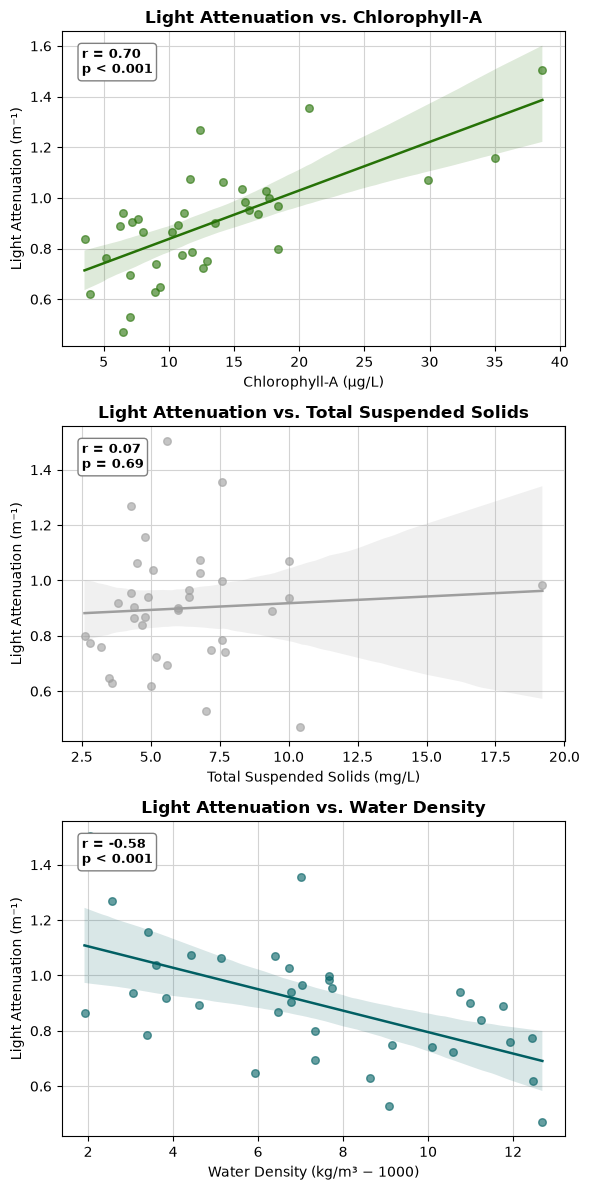

In [18]:
# A reusable function to display p-values: two decimal places, or 'p < 0.001' / 'p < 0.05' for small values
def format_p(p):
    if p < 0.001:
        return "p < 0.001"
    if p < 0.05:
        return "p < 0.05"
    return f"p = {p:.2f}"

# A reusable function that draws one scatter plot of KD vs. a candidate input variable
# with a fitted linear regression line (and its 95% confidence band) and the correlation coefficient
def scatter_vs_kd(ax, var, color):
    ax.set_axisbelow(True)
    ax.grid(True, color='lightgray')

    # regplot draws a scatter plot with a fitted linear regression line overlaid
    sns.regplot(x=wide[var], y=wide[target], ax=ax, color=color,
                scatter_kws={'alpha': 0.6, 's': 30}, line_kws={'linewidth': 1.8})

    # Pearson correlation coefficient and p-value
    r, p = stats.pearsonr(wide[var], wide[target])
    ax.text(0.04, 0.95, f"r = {r:.2f}\n{format_p(p)}", transform=ax.transAxes, ha='left', va='top',
            fontsize=9, fontweight='bold', bbox=dict(boxstyle='round', facecolor='white', edgecolor='gray'))
    ax.set_xlabel(axis_label(var))
    ax.set_ylabel(axis_label(target))
    ax.set_title(f"{alt_name[target]} vs. {alt_name[var]}", fontweight='bold')

print("Scatter plots: KD vs. each of the original chosen input variables (Chlorophyll-A, Total Suspended Solids, Water Density)")
print("Gray plot = variable not selected for regression analyses")
orig_inputs = ['CHLA', 'TSS', 'SIGMA_T']
orig_colors = {'CHLA': var_colors['CHLA'], 'TSS': other_color, 'SIGMA_T': var_colors['SIGMA_T']}

fig, axes = plt.subplots(len(orig_inputs), 1, figsize=(6,12), dpi=100)
for ax, var in zip(axes, orig_inputs):
    scatter_vs_kd(ax, var, orig_colors[var])
plt.tight_layout()
plt.show()

Scatter plots: KD vs. additional candidate input variables (Particulate Phosphorus, Total Phosphorus, Particulate Carbon)
Gray plot = variable not selected for regression analyses


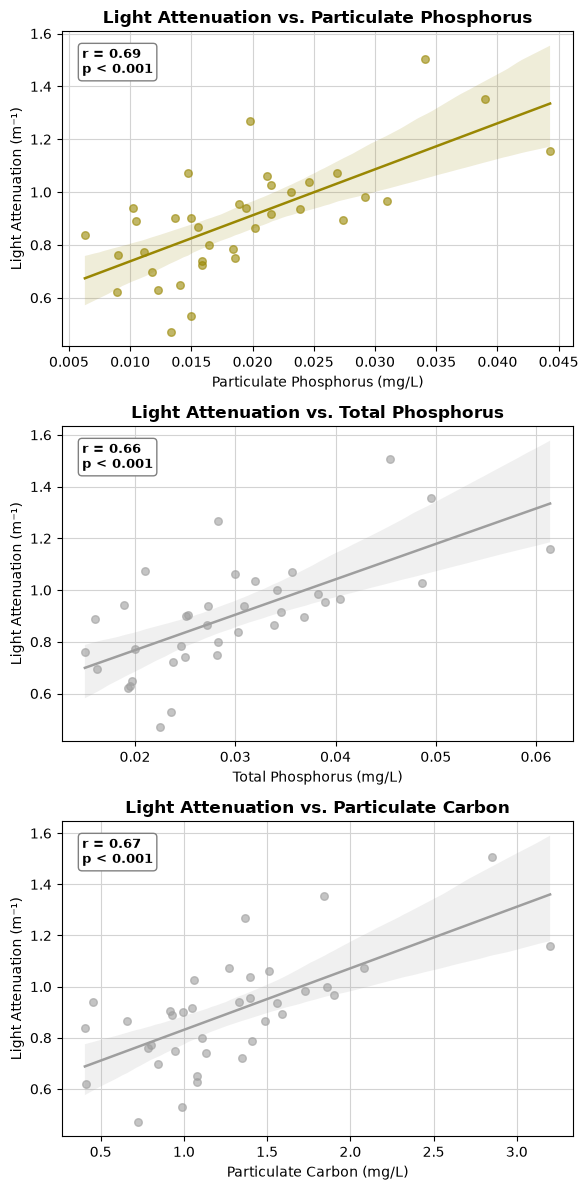

In [19]:
print("Scatter plots: KD vs. additional candidate input variables (Particulate Phosphorus, Total Phosphorus, Particulate Carbon)")
print("Gray plot = variable not selected for regression analyses")
extra_inputs = ['PP', 'TP', 'PC']
extra_colors = {'PP': var_colors['PP'], 'TP': other_color, 'PC': other_color}

fig, axes = plt.subplots(len(extra_inputs), 1, figsize=(6,12), dpi=100)
for ax, var in zip(axes, extra_inputs):
    scatter_vs_kd(ax, var, extra_colors[var])
plt.tight_layout()
plt.show()

--------------------------------------------------------------------------------------

The scatter plots show the linear relationship between `KD` and each candidate. Each plot shows the fitted line, its 95% confidence band, and the correlation coefficient:
- **Chlorophyll-A:** a clear positive trend (r = 0.70, p < 0.001). `KD` increases with chlorophyll across the whole range, and the highest chlorophyll sample (38.7 μg/L) also has the highest `KD` (1.5 m⁻¹). There is still a lot of spread around the line, especially between 5 and 20 μg/L.
- **Water Density:** a clear negative trend (r = -0.58, p < 0.001), with more scatter than chlorophyll. The highest `KD` values occur at low density (fresher water).
- **Total Suspended Solids:** **no meaningful trend** (r = 0.07, p = 0.69). Even though suspended particles are expected to make the water more turbid, `TSS` does not seem to have a strong relationship with `KD` in this dataset. A possible explanation is that `TSS` measures the total *mass* of particles, while the attenuation of light depends on the number, size, and composition of particles (e.g., a small number of heavy sediment particles can contribute lots of mass but little light scattering) and on dissolved colored material that is not captured by `TSS` at all (Gallegos, 2001; Kirk, 2011). The fitted line is also pulled around by a single high value (19.2 mg/L).
- **Particulate Phosphorus:** a clear positive trend (r = 0.69, p < 0.001), almost as strong as chlorophyll, and much stronger than `TSS`.
- **Total Phosphorus** (r = 0.66) and **Particulate Carbon** (r = 0.67) show similar positive trends, but as explained in 02.2, they overlap heavily with `PP` and `CHLA`.

**Decision:** `TSS` is dropped as an input and replaced with `PP`. `PP` is just as strongly related to `KD` as the best input (`CHLA`), is measured on every sampling date with no quality flags, and, like `TSS`, indicates the water's particle load. None of the other variables examined has a stronger relationship with `KD` than `CHLA` or `PP` without being redundant with them or being a measure of clarity itself. The three final inputs are therefore **`CHLA`, `SIGMA_T`, and `PP`**.

--------------------------------------------------------------------------------------

### 02.4 Descriptive Statistics and Distributions of the Final Variables

With the three inputs selected (`CHLA`, `SIGMA_T`, and `PP`), summarize and visualize them together with the target (`KD`).

In [20]:
# Final choice of target and inputs (explained at the end of this section)
target = 'KD'
features = ['CHLA', 'SIGMA_T', 'PP']

# Descriptive statistics (count, mean, std, min, quartiles, max) of the target and the three chosen input variables
print("Descriptive statistics for the target and the three chosen input variables:")
desc = wide[[target] + features].describe().T.round(4)
desc.insert(0, 'Units', [get_units(c) for c in desc.index])
desc.index = [alt_name[c] for c in desc.index]
desc

Descriptive statistics for the target and the three chosen input variables:


,Units,count,mean,std,min,25%,50%,75%,max
Light Attenuation,m⁻¹,37.0,0.8994,0.2138,0.4700,0.7609,0.9015,0.9990,1.5051
Chlorophyll-A,μg/L,37.0,13.2124,7.8529,3.5240,7.5950,11.6290,16.1730,38.6620
Water Density,kg/m³ − 1000,37.0,7.3145,3.2064,1.9155,4.6165,7.0340,10.0915,12.6889
Particulate Phosphorus,mg/L,37.0,0.0193,0.0085,0.0063,0.0137,0.0184,0.0231,0.0443


Histograms: distributions of the target and the three input variables


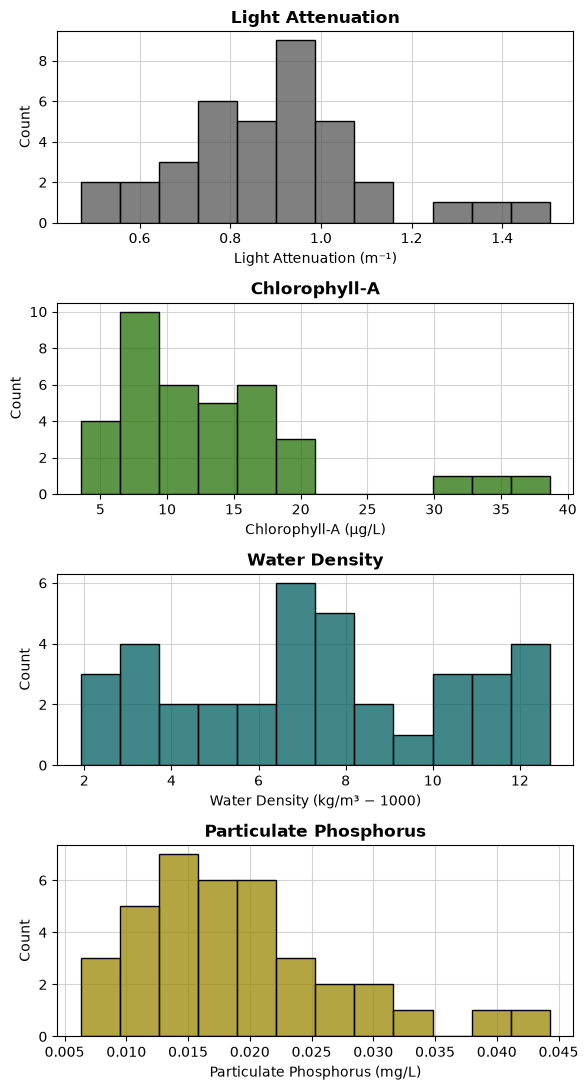

In [21]:
print("Histograms: distributions of the target and the three input variables")

fig, axes = plt.subplots(4, 1, figsize=(6,11), dpi=100)
for ax, var in zip(axes, [target] + features):
    # Draw a light gray grid first, and push it behind the plotted bars
    ax.set_axisbelow(True)
    ax.grid(True, color='lightgray')
    sns.histplot(data=wide, x=var, bins=12, color=var_colors[var], ax=ax)
    ax.set_xlabel(axis_label(var))
    ax.set_title(alt_name[var], fontweight='bold')
plt.tight_layout()
plt.show()

In [22]:
# Skewness of each variable (0 = symmetric; positive = long tail of high values)
print("Skewness of each variable:")
wide[[target] + features].skew().round(2).rename(index=alt_name)

Skewness of each variable:


Light Attenuation         0.57
Chlorophyll-A             1.70
Water Density             0.07
Particulate Phosphorus    1.09
dtype: float64

--------------------------------------------------------------------------------------

- **Light Attenuation (`KD`)** has a mean of 0.90 m⁻¹ and a median of 0.90 m⁻¹, and its histogram is roughly bell-shaped (skewness 0.57), with a few high values from 1.25 to 1.5 m⁻¹. This is a good shape for a regression target.
- **Chlorophyll-A** is right-skewed (skewness 1.70; mean 13.2 vs. median 11.6 μg/L): most samples are below 20 μg/L, and only 3 samples exceed 25 μg/L (maximum 38.7 μg/L).
- **Water Density** is the most symmetrical (skewness 0.07) and spread over its whole range (1.9 to 12.7), with no single dominant mode. This reflects the large swings between fresher and saltier water at this site.
- **Particulate Phosphorus** is right-skewed (skewness 1.09; mean 0.019 vs. median 0.018 mg/L), with 4 samples above 0.03 mg/L (maximum 0.044 mg/L).

The skewed tails matter because only a handful of samples cover the high-chlorophyll, high-phosphorus, and high-`KD` end of the range. A single extreme sample can heavily influence a fitted line, and the more flexible models (KNN and Radius Neighbors) have almost no data to learn from at that end.

--------------------------------------------------------------------------------------

--------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------

### SECTION 02 SUMMARY: Reasoning for Input Variable Choices

**Summary of findings of this section:** after removing 5 impossible `KD` values (leaving 37 samples), `CHLA` (r = 0.70) and `PP` (r = 0.69) were the strongest individual correlates of `KD`, `SIGMA_T` was moderately correlated (r = -0.58), and `TSS` (r = 0.07) had no meaningful relationship with `KD` even though one would be expected. `TSS` was therefore replaced by `PP`.

**Target variable:** Light Attenuation (`KD`, m⁻¹), an integrative measure of water clarity that matters for light availability to phytoplankton and submerged aquatic vegetation (Dennison et al., 1993; Kirk, 2011).

**Final input (predictor) variables, each used in its own separate regression:**

1. **Chlorophyll-A (`CHLA`, μg/L)**
   - *Scientific reasoning:* Chlorophyll-a is the main photosynthetic pigment of phytoplankton, and phytoplankton absorb and scatter light, so higher chlorophyll means higher light attenuation. Phytoplankton are one of the major components of `KD` in estuaries (Gallegos, 2001; Kirk, 2011), chlorophyll-a is one of the water quality variables used to define SAV habitat requirements (Dennison et al., 1993), and nutrient-driven algal blooms are a major driver of reduced clarity in the Chesapeake Bay (Kemp et al., 2005).
   - *Dataset-specific reasoning:* It has the strongest correlation with `KD` of all variables (r = 0.70, p < 0.001; a linear fit explains about 49% of the variance of `KD`), has no flagged or missing values, and spans a wide range (3.5 to 38.7 μg/L).

2. **Water Density (`SIGMA_T`, kg/m³ − 1000)**
   - *Scientific reasoning:* Seawater density depends on salinity and temperature (Talley et al., 2011), so it tracks the mixture of fresh river water and saltier Bay water. In the upper Bay, discharge from the Susquehanna River strongly controls the salinity (Schubel & Pritchard, 1986) and also supplies sediment and nutrients that reduce clarity (Kemp et al., 2005), so water density is an indicator of this physical, river-driven control on `KD` rather than a direct optical constituent. This makes it a physically different type of input than the two particle-related variables.
   - *Dataset-specific reasoning:* It has a moderate negative correlation with `KD` (r = -0.58, p < 0.001), is the most symmetrically distributed of the inputs, and combines the information of `SALINITY` and `WTEMP` (which are not used separately because `SALINITY` is almost redundant with it, r = 0.88). It is only moderately correlated with `CHLA` (r = -0.49), so it brings different information. It also has no flagged or missing values.

3. **Particulate Phosphorus (`PP`, mg/L)**
   - *Scientific reasoning:* In estuaries, phosphorus is commonly attached to sediment particles and incorporated into algal biomass (Correll, 1998), so `PP` is a measure of the amount of suspended particulate material (both living algae and sediment) that scatters and absorbs light (Gallegos, 2001), and it is directly tied to the nutrient enrichment that drives reduced water clarity in the Bay (Kemp et al., 2005). It is therefore a measured stand-in for the particle load that Total Suspended Solids (`TSS`) was originally expected to represent.
   - *Dataset-specific reasoning:* It is almost as strongly correlated with `KD` as `CHLA` (r = 0.69, p < 0.001), whereas `TSS` has no relationship with it (r = 0.07), and it is measured on every date with no quality flags. It is correlated with `CHLA` (r = 0.82), but because the regressions are run separately this does not cause problems, and comparing the two inputs shows whether the particle load adds anything beyond chlorophyll.

*Variables not used as inputs:* `TSS` (no relationship with `KD`), `SECCHI` (another measure of clarity rather than a driver), `SALINITY` and `WTEMP` (the ingredients of `SIGMA_T`), and `PC`, `PN`, and `TP` (heavily redundant with `CHLA` and `PP`).

--------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------

--------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------

## 03) Train/Test Split

Each model is **fit on a training set** and then judged on a **test set** that it has never seen, which shows how well it generalizes rather than just how well it memorized the data. With only a few dozen samples, the split is small, so cross-validation (repeatedly re-splitting the training data) is also used inside the hyperparameter searches and as a more stable score. The same split is used for all three inputs and all three models so that they can be compared fairly. Each input variable is standardized (mean 0, standard deviation 1) inside a `Pipeline`, so the scaler is fit on training data only and no information leaks from the test set. **Cross-validated R²** in this notebook is defined as 1 − (mean squared error on the validation folds) ÷ (variance of `KD` in the training data), so, like a normal R², 0 means "no better than always predicting the mean" and 1 is a perfect prediction.

--------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------

### 03.1 Splitting the Data

Randomly hold out 25% of the samples as the test set.

In [23]:
# Define the inputs (X) and the target (y)
X = wide[features]
y = wide[target]

# Split into 75% training and 25% test data
# random_state fixes the random shuffle so the notebook gives the same results every time it is run
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

print(f"Total samples: {len(X)}")
print(f"Training samples: {len(X_train)}")
print(f"Test samples: {len(X_test)}")

Total samples: 37
Training samples: 27
Test samples: 10


In [24]:
# Check that the training and test sets look similar (KD summary statistics for each set)
print("Light Attenuation (KD, m⁻¹) in the training vs. test set:")
pd.DataFrame({'Training': y_train.describe(), 'Test': y_test.describe()}).round(3)

Light Attenuation (KD, m⁻¹) in the training vs. test set:


,Training,Test
count,27.000,10.000
mean,0.895,0.912
std,0.219,0.211
min,0.470,0.530
25%,0.746,0.809
50%,0.903,0.880
75%,0.991,1.031
max,1.505,1.268


### 03.2 Evaluation Settings and Baseline

Define the cross-validation settings and a 'no-skill' baseline model that every real model should beat.

In [25]:
# Settings shared by all of the hyperparameter searches below:
# 5-fold cross-validation repeated 5 times (25 train/validation splits of the TRAINING data only)
cv = RepeatedKFold(n_splits=5, n_repeats=5, random_state=42)

techniques = ['Polynomial Regression', 'KNN', 'Radius Neighbors']

# Dictionary to collect every fitted model: fitted[(input variable, technique)] -> model, search object, CV score
fitted = {}

# Helper function: builds a pipeline that standardizes the input and then applies the model
def make_pipe(estimator):
    return Pipeline([('scale', StandardScaler()), ('model', estimator)])

# ---- Cross-validated R² ----
# Each validation fold only holds ~5 samples, so an R² calculated within each fold is very noisy and harsh.
# Instead, the searches below score each combination with the mean squared error (MSE) over the validation folds,
# and the result is converted to an R²-style score:  CV R² = 1 - (mean validation MSE) / (variance of KD in the training data).
# Like a normal R², 0 means "no better than always predicting the mean" and 1 is a perfect prediction.
var_y = np.var(y_train)

def mse_score_to_r2(neg_mse):
    # converts a scikit-learn 'neg_mean_squared_error' score into the cross-validated R² described above
    return 1 + neg_mse / var_y

def cv_r2_score(estimator, X_in):
    neg_mse = cross_val_score(estimator, X_in, y_train, cv=cv, scoring='neg_mean_squared_error').mean()
    return mse_score_to_r2(neg_mse)

In [26]:
# Baseline: a model that ignores the inputs and always predicts the mean KD of the training data.
# Its R² is close to (or slightly below) 0 by definition, so any useful model should score higher.
baseline = DummyRegressor(strategy='mean')
baseline.fit(X_train, y_train)

baseline_scores = {'Train R²': r2_score(y_train, baseline.predict(X_train)),
                   'CV R² (train)': cv_r2_score(baseline, X_train),
                   'Test R²': r2_score(y_test, baseline.predict(X_test))}
print("Baseline (always predict the training mean):")
pd.Series(baseline_scores).round(3)

Baseline (always predict the training mean):


Train R²         0.000
CV R² (train)   -0.082
Test R²         -0.007
dtype: float64

--------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------

### SECTION 03 SUMMARY: Training and Test Sets

**Findings of this section:**
- The 37 clean samples were split into **27 training samples and 10 test samples** (75%/25%), using the same split for every input variable and every model so that they can be compared fairly.
- The training and test sets have similar `KD` distributions (mean 0.895 vs. 0.912 m⁻¹, standard deviation 0.219 vs. 0.211 m⁻¹). The test set does not include the highest `KD` value (maximum 1.27 vs. 1.51 m⁻¹ in training), so it covers a slightly narrower range of `KD` values.
- The "no-skill" baseline (always predicting the mean training `KD`) scores a test R² of about 0 (-0.007) and a cross-validated R² of -0.08. Any useful model needs to beat these scores.
- With only 10 test samples, a single test score can easily be misleading, so in Section 06 the cross-validated R² and a 100-split repeated test are used alongside the test R².

--------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------

--------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------

## 04) Model Implementation

Three techniques are fitted with `scikit-learn` (Pedregosa et al., 2011), each one separately for each of the three input variables:

**(a) Polynomial regression**, ordinary least squares fitted to the input and its powers (x, x², ..., x^degree); with degree 1 this is a simple linear regression (a straight line)

**(b) k-Nearest Neighbors (KNN) regression**, a flexible technique that predicts the average `KD` of the most similar past samples (the `k` nearest samples) and can follow either linear or non-linear relationships (Hastie et al., 2009)

**(c) Radius Neighbors regression**, similar to KNN, but it predicts the average `KD` of *all* training samples within a fixed distance (the radius) of the new sample instead of a fixed number of samples

Hyperparameters for all three techniques (the polynomial degree, `k`, and the radius) are chosen **automatically** by `GridSearchCV`, which tries every combination in a grid and picks the one with the best cross-validated score (lowest validation error, i.e., highest cross-validated R²) on the *training* data, so the notebook runs from start to finish without any user input. The test set is never used to choose hyperparameters.

Only **one version of each technique is used for each input**: the first subsection checks whether the relationship between `KD` and each input is better described as linear or non-linear, which sets how the polynomial and Radius Neighbors models are labeled and interpreted. KNN is used in its non-linear form for every input (see 04.1). Because every regression uses a single input, a degree-1 polynomial regression is a *simple* linear regression (ordinary least squares); a *multiple* linear regression would require several inputs in the same model.

--------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------

### 04.1 Choosing Linear or Non-linear Model Types

For each input, check whether a curved relationship describes `KD` better than a straight line. A straight line (degree 1) is compared with a quadratic (degree 2) and a cubic (degree 3) polynomial using cross-validation on the training data.

In [27]:
# Compare a straight line with curved (polynomial) fits for each input variable, using the cross-validated R²
# (defined in Section 03: 0 = no better than always predicting the mean, 1 = perfect)
poly_rows = []
for var in features:
    row = {'Input': alt_name[var]}
    for degree, name in [(1, 'Straight line (degree 1)'), (2, 'Quadratic (degree 2)'), (3, 'Cubic (degree 3)')]:
        pipe = Pipeline([('scale', StandardScaler()),
                         ('poly', PolynomialFeatures(degree=degree, include_bias=False)),
                         ('model', LinearRegression())])
        row[name] = cv_r2_score(pipe, X_train[[var]])
    poly_rows.append(row)
poly_table = pd.DataFrame(poly_rows).set_index('Input')

print("Cross-validated R² of a straight line vs. curved polynomial fits:")
poly_table.round(2)

Cross-validated R² of a straight line vs. curved polynomial fits:


,Straight line (degree 1),Quadratic (degree 2),Cubic (degree 3)
Input,,,
Chlorophyll-A,0.54,0.40,-1.19
Water Density,0.15,-0.03,-0.17
Particulate Phosphorus,0.51,0.50,0.02


In [28]:
# Decision rule: an input is treated as 'Non-linear' only if a curved fit improves the cross-validated R²
# by more than 0.05 over the straight line; otherwise it is treated as 'Linear'
model_type = {}
for var in features:
    row = poly_table.loc[alt_name[var]]
    best_curved = max(row['Quadratic (degree 2)'], row['Cubic (degree 3)'])
    model_type[var] = 'Non-linear' if best_curved > row['Straight line (degree 1)'] + 0.05 else 'Linear'

print("Model type used for each input variable:")
for var in features:
    print(f"  {alt_name[var]:25s} -> {model_type[var]}")

# KNN is always used in its non-linear form (see the note below); polynomial regression and Radius Neighbors follow the rule above
def technique_type(var, tech):
    return 'Non-linear' if tech == 'KNN' else model_type[var]

# Nicer model names used in the plot titles and printed results
def model_title(var, tech):
    if tech == 'Polynomial Regression':
        degree = fitted[(var, tech)]['model'].named_steps['poly'].degree
        return f"Polynomial Regression (Degree {degree}, {technique_type(var, tech)})"
    return f"{technique_type(var, tech)} {tech} Regression"


Model type used for each input variable:
  Chlorophyll-A             -> Linear
  Water Density             -> Linear
  Particulate Phosphorus    -> Linear


--------------------------------------------------------------------------------------

**Result:** for all three inputs, a straight line is as good as or better than a curved fit, so **all three relationships are treated as linear**.
- **Chlorophyll-A:** the straight line (cross-validated R² of 0.54) beats the quadratic (0.40) and the cubic (-1.19) fits. The scatter plot in Section 02 shows a hint of leveling-off at the highest chlorophyll values, but only 3 samples exceed 25 μg/L, which is not enough to support a curved model.
- **Water Density:** the straight line (0.15) is better than the quadratic (-0.03) and the cubic (-0.17) fits.
- **Particulate Phosphorus:** the straight line (0.51) and the quadratic (0.50) are nearly identical, and the cubic is worse (0.02), so there is no evidence of curvature.

Higher-degree polynomials fit the noise in these 27 training samples and score worse in cross-validation, so a more flexible curve is not justified. (The polynomial degree is also tuned formally as a hyperparameter in 04.2, over degrees 1 to 8, with the same result.)

**How the model types are used:**
- **Polynomial regression** and **Radius Neighbors** are labeled **linear** for all three inputs, following this result. For the polynomial regression, the selected degree of 1 makes it a simple linear regression (ordinary least squares with a single input); a *multiple* linear regression is not used because each regression has only one input.
- **KNN** is used in its **non-linear** form for all three inputs. KNN does not assume any shape: its prediction is a step-like curve that can bend wherever the data bend, so it serves as the flexible model that would pick up any curvature the straight line misses. As in the class examples, the linear and non-linear versions of KNN use the same algorithm (`KNeighborsRegressor`); the label describes how the model is used and interpreted (and the fitted line is always drawn at full resolution, so its real step-like shape is visible).

--------------------------------------------------------------------------------------

### 04.2 Polynomial Regression

Polynomial regression fits `KD` = b₀ + b₁·x + b₂·x² + ... + b_d·x^d by ordinary least squares, where x is the input and d is the **degree**, the hyperparameter. Degree 1 is a straight line (a simple linear regression); each additional degree lets the curve bend once more. The degree is tuned automatically for each input from 1 to 8. (The input is standardized before the powers are calculated; otherwise the powers of the input would have wildly different sizes, e.g., Chlorophyll-A⁸ ≈ 10¹² μg⁸/L⁸, and the least-squares solution would lose precision. This does not change the fitted curve.)

In [29]:
# Hyperparameter to search:
#   poly__degree: the polynomial degree, 1 (straight line = simple linear regression) to 8
poly_grid = {'poly__degree': list(range(1, 9))}

# Pipeline: standardize the input -> create the powers of the input (x, x², ..., x^degree) -> ordinary least squares
def make_poly_pipe():
    return Pipeline([('scale', StandardScaler()),
                     ('poly', PolynomialFeatures(include_bias=False)),
                     ('model', LinearRegression())])

# Run the grid search separately for each input variable; the best model is refit on the whole training set
for var in features:
    search = GridSearchCV(make_poly_pipe(), poly_grid, cv=cv, scoring='neg_mean_squared_error')
    search.fit(X_train[[var]], y_train)
    fitted[(var, 'Polynomial Regression')] = {'model': search.best_estimator_, 'cv_r2': mse_score_to_r2(search.best_score_), 'search': search}

In [30]:
# Convert the fitted polynomial (in standardized units) back to the original units of each input,
# so the fitted model can be written as KD = b0 + b1*x + b2*x² + ... (x in the original units)
def poly_coefficients(var):
    pipe = fitted[(var, 'Polynomial Regression')]['model']
    scaler, lin = pipe.named_steps['scale'], pipe.named_steps['model']
    p_z = np.polynomial.Polynomial(np.r_[lin.intercept_, lin.coef_])                            # KD as a polynomial of z
    z_of_x = np.polynomial.Polynomial([-scaler.mean_[0] / scaler.scale_[0], 1 / scaler.scale_[0]])  # z = (x - mean) / std
    return p_z(z_of_x).coef                                                                        # b0, b1, b2, ... for x

superscripts = str.maketrans('0123456789', '⁰¹²³⁴⁵⁶⁷⁸⁹')
def poly_equation(var):
    b = poly_coefficients(var)
    eq = f"{alt_name[target]} = {b[0]:.4g}"
    for power, coef in enumerate(b[1:], start=1):
        term = alt_name[var] if power == 1 else alt_name[var] + str(power).translate(superscripts)
        eq += f" {'+' if coef >= 0 else '−'} {abs(coef):.4g} × {term}"
    return eq

rows = []
for var in features:
    s = fitted[(var, 'Polynomial Regression')]['search']
    rows.append({'Input': alt_name[var], 'Model type': model_type[var], 'Best degree': s.best_params_['poly__degree'],
                 'Best cross-validated R²': round(mse_score_to_r2(s.best_score_), 3), 'Fitted equation (input in its original units)': poly_equation(var)})
print("Best polynomial degree and fitted equation for each input variable:")
pd.DataFrame(rows).set_index('Input')

Best polynomial degree and fitted equation for each input variable:


,Model type,Best degree,Best cross-validated R²,Fitted equation (input in its original units)
Input,,,,
Chlorophyll-A,Linear,1,0.544,Light Attenuation = 0.5904 + 0.02263 × Chlorop...
Water Density,Linear,1,0.153,Light Attenuation = 1.155 − 0.03478 × Water De...
Particulate Phosphorus,Linear,1,0.505,Light Attenuation = 0.4821 + 21.5 × Particulat...


--------------------------------------------------------------------------------------

The grid search selected **degree 1 (a straight line) for all three inputs**, so the polynomial regressions are simple linear regressions, with cross-validated R² of 0.54 (Chlorophyll-A), 0.15 (Water Density), and 0.51 (Particulate Phosphorus). Why higher degrees were rejected is shown in Section 05.

All three fitted lines have the sign expected from the physical reasoning in Section 02:
- **Chlorophyll-A:** `KD` increases by about 0.023 m⁻¹ for each additional 1 μg/L of chlorophyll (about 0.23 m⁻¹ per 10 μg/L).
- **Water Density:** `KD` decreases by about 0.035 m⁻¹ for each additional 1 kg/m³ of density.
- **Particulate Phosphorus:** `KD` increases by about 0.22 m⁻¹ for each additional 0.01 mg/L of particulate phosphorus.

The intercepts are not zero (0.48 to 1.16 m⁻¹), which makes sense since a sample with no chlorophyll or phosphorus would still attenuate light because of the water itself, dissolved colored material, and other particles (Kirk, 2011).

--------------------------------------------------------------------------------------

### 04.3 k-Nearest Neighbors (KNN) Regression

KNN predicts `KD` for a sample by averaging the `KD` of its k most similar training samples (similarity = distance in the standardized input space). The number of neighbors (k) and the weighting scheme are tuned automatically for each input.

In [31]:
# Hyperparameters to search:
#   n_neighbors: k = 1 to 15
#   weights: 'uniform' (all k neighbors count equally) or 'distance' (closer neighbors count more)
knn_grid = {'model__n_neighbors': list(range(1, 16)),
            'model__weights': ['uniform', 'distance']}

# Run the grid search separately for each input variable; the best model is refit on the whole training set
for var in features:
    search = GridSearchCV(make_pipe(KNeighborsRegressor()), knn_grid, cv=cv, scoring='neg_mean_squared_error')
    search.fit(X_train[[var]], y_train)
    fitted[(var, 'KNN')] = {'model': search.best_estimator_, 'cv_r2': mse_score_to_r2(search.best_score_), 'search': search}

In [32]:
# Show the automatically selected hyperparameters
rows = []
for var in features:
    s = fitted[(var, 'KNN')]['search']
    rows.append({'Input': alt_name[var], 'Model type': technique_type(var, 'KNN'), 'Best k': s.best_params_['model__n_neighbors'],
                 'Best weights': s.best_params_['model__weights'], 'Best cross-validated R²': mse_score_to_r2(s.best_score_)})
print("Best KNN hyperparameters for each input variable:")
pd.DataFrame(rows).set_index('Input').round(3)

Best KNN hyperparameters for each input variable:


,Model type,Best k,Best weights,Best cross-validated R²
Input,,,,
Chlorophyll-A,Non-linear,5,uniform,0.372
Water Density,Non-linear,12,uniform,0.071
Particulate Phosphorus,Non-linear,4,distance,0.434


--------------------------------------------------------------------------------------

The grid search selected **k = 5 (uniform weights) for Chlorophyll-A**, **k = 12 (uniform weights) for Water Density**, and **k = 4 (distance weights) for Particulate Phosphorus**, with cross-validated R² of 0.37, 0.07, and 0.43. All three are used as non-linear KNN regressions (see 04.1). The reasoning behind these choices is discussed in Section 05.

--------------------------------------------------------------------------------------

### 04.4 Radius Neighbors Regression

Radius Neighbors predicts `KD` for a sample by averaging the `KD` of all training samples within a fixed distance (the radius) of it, so the number of neighbors changes with how crowded the data are (scikit-learn developers, 2026). The radius and the weighting scheme are tuned automatically for each input.

In [33]:
# scikit-learn's RadiusNeighborsRegressor returns NaN (and a warning) for a sample that has NO training samples
# within the radius, which would break the cross-validation for small radii. This small wrapper predicts the mean of the
# training data in that case, so every radius in the search can be scored.
class SafeRadiusNeighborsRegressor(RadiusNeighborsRegressor):
    def fit(self, X, y):
        self.fallback_ = float(np.mean(y))
        return super().fit(X, y)

    def predict(self, X):
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            pred = super().predict(X)
        return np.where(np.isnan(pred), self.fallback_, pred)

In [34]:
# Hyperparameters to search (the inputs are standardized, so the radius is in units of standard deviations of the input):
#   radius: from 0.1 to 3 standard deviations
#   weights: 'uniform' (all neighbors in the radius count equally) or 'distance' (closer neighbors count more)
rnr_grid = {'model__radius': [0.1, 0.2, 0.3, 0.4, 0.5, 0.75, 1, 1.5, 2, 3],
            'model__weights': ['uniform', 'distance']}

# Run the grid search separately for each input variable; the best model is refit on the whole training set
for var in features:
    search = GridSearchCV(make_pipe(SafeRadiusNeighborsRegressor()), rnr_grid, cv=cv, scoring='neg_mean_squared_error')
    search.fit(X_train[[var]], y_train)
    fitted[(var, 'Radius Neighbors')] = {'model': search.best_estimator_, 'cv_r2': mse_score_to_r2(search.best_score_), 'search': search}

In [35]:
# Show the automatically selected hyperparameters (the radius is also converted back to the original units of each input)
rows = []
for var in features:
    s = fitted[(var, 'Radius Neighbors')]['search']
    radius_sd = s.best_params_['model__radius']
    rows.append({'Input': alt_name[var], 'Model type': model_type[var],
                 'Best radius (std. devs.)': radius_sd,
                 f'Best radius (input units)': f"{radius_sd * X_train[var].std(ddof=0):.4g} {get_units(var)}",
                 'Best weights': s.best_params_['model__weights'],
                 'Best cross-validated R²': mse_score_to_r2(s.best_score_)})
print("Best Radius Neighbors hyperparameters for each input variable:")
pd.DataFrame(rows).set_index('Input').round(3)

Best Radius Neighbors hyperparameters for each input variable:


,Model type,Best radius (std. devs.),Best radius (input units),Best weights,Best cross-validated R²
Input,,,,,
Chlorophyll-A,Linear,0.75,5.554 μg/L,uniform,0.212
Water Density,Linear,1.50,4.818 kg/m³ − 1000,uniform,0.120
Particulate Phosphorus,Linear,1.50,0.01145 mg/L,distance,0.425


--------------------------------------------------------------------------------------

The grid search selected a radius of **0.75 standard deviations (5.55 μg/L) with uniform weights for Chlorophyll-A**, **1.5 standard deviations (4.82 kg/m³) with uniform weights for Water Density**, and **1.5 standard deviations (about 0.011 mg/L) with distance weights for Particulate Phosphorus**, with cross-validated R² of 0.21, 0.12, and 0.42. The `SafeRadiusNeighborsRegressor` wrapper was only needed to keep the cross-validation from failing for very small radii (a sample with no neighbors gets the training mean); none of the 10 test samples had an empty neighborhood at the selected radii. The reasoning behind the radii is discussed in Section 05.

--------------------------------------------------------------------------------------

--------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------

### SECTION 04 SUMMARY: Model Types and Fitted Models

**Findings of this section:**
- A check of straight-line vs. curved (quadratic and cubic) fits showed that **a straight line is the best description of all three relationships** (Chlorophyll-A, Water Density, and Particulate Phosphorus). The polynomial and Radius Neighbors regressions are therefore labeled linear, and KNN is used in its non-linear (flexible) form, so one version of each technique is used for each input.
- Nine models were fit (3 techniques x 3 inputs). All hyperparameters (polynomial degree, `k`, radius, and weights) were selected automatically by cross-validation on the training data only.
- **Polynomial regression** selected **degree 1 for every input**, i.e., a simple linear regression (ordinary least squares), with physically sensible slopes (`KD` increases with chlorophyll and particulate phosphorus and decreases with water density).
- **KNN** selected k = 5 (Chlorophyll-A), k = 12 (Water Density), and k = 4 (Particulate Phosphorus). **Radius Neighbors** selected radii of 0.75, 1.5, and 1.5 standard deviations.
- The cross-validated R² scores were highest for the polynomial (degree 1) regressions of Chlorophyll-A (0.54) and Particulate Phosphorus (0.51), and the KNN and Radius Neighbors scores were lower or similar (0.21 to 0.43 for these two inputs). All the Water Density models scored low (0.07 to 0.15).

--------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------

--------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------

## 05) Hyperparameter Explanation

This section explains which hyperparameters worked for each model and why. The hyperparameters (polynomial degree, `k`, and radius) were not chosen by hand: for every input variable, `GridSearchCV` tested each combination of hyperparameters with 5-fold cross-validation repeated 5 times on the training data (25 train/validation splits) and kept the combination with the lowest mean squared error on the validation folds (i.e., the highest cross-validated R²). The following cells show the evidence behind each choice. 

--------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------

### 05.1 Polynomial Regression: How Was the Degree Chosen?

The degree controls how flexible the polynomial is: degree 1 is a straight line, and every additional degree lets the curve bend once more. A higher degree always fits the *training* data at least as well, but with few samples the extra bends follow noise, and the curve can swing to extreme values between and beyond the data points. The cross-validated R² for every degree is shown for each input.

Plots: cross-validated R² as a function of the polynomial degree for each input variable
(scores below -1 are drawn at -1 so the useful part of the plot stays readable; the exact values are in the table below)


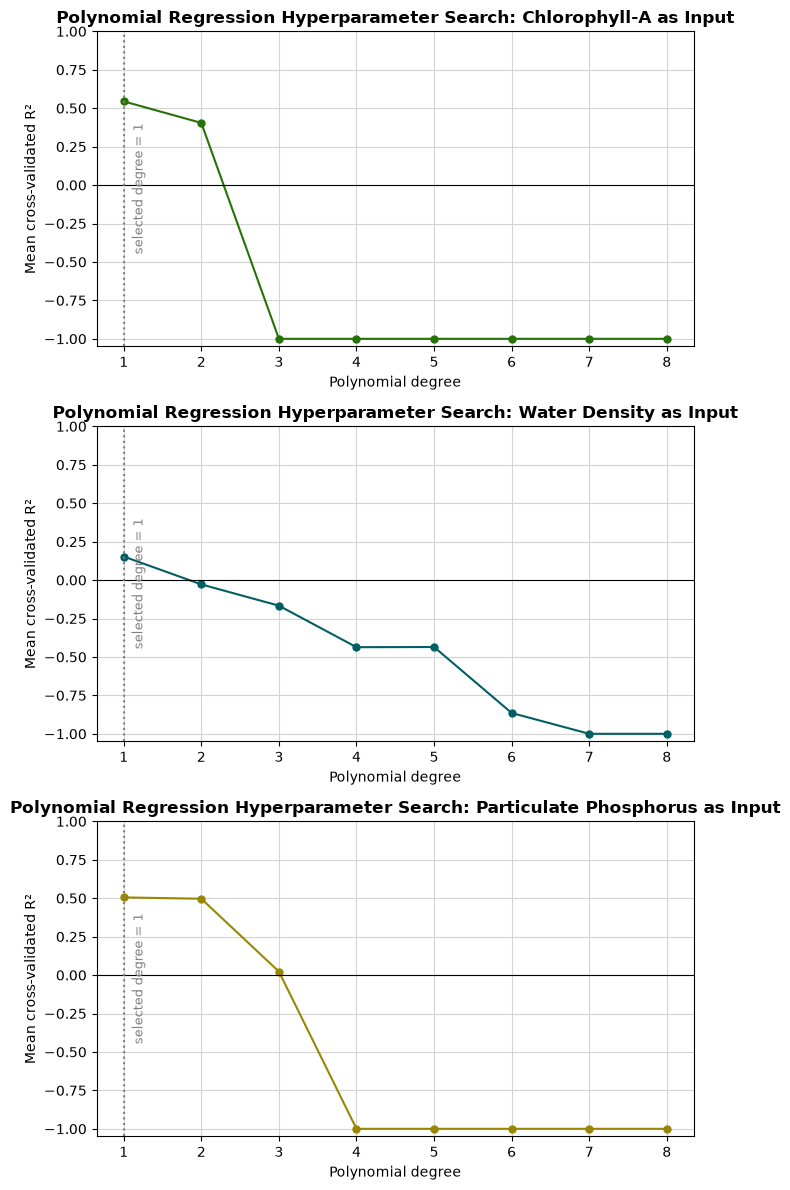

In [36]:
print("Plots: cross-validated R² as a function of the polynomial degree for each input variable")
print("(scores below -1 are drawn at -1 so the useful part of the plot stays readable; the exact values are in the table below)")

fig, axes = plt.subplots(len(features), 1, figsize=(7,4*len(features)), dpi=100)
for ax, var in zip(axes, features):
    s = fitted[(var, 'Polynomial Regression')]['search']
    res = pd.DataFrame(s.cv_results_)
    res['degree'] = res['param_poly__degree'].astype(int)
    res['cv_r2'] = mse_score_to_r2(res['mean_test_score'])   # convert the MSE-based score to a cross-validated R²

    ax.set_axisbelow(True)
    ax.grid(True, color='lightgray')
    ax.plot(res['degree'], res['cv_r2'].clip(lower=-1), '-', marker='o', markersize=5, color=var_colors[var])
    ax.axhline(0, color='black', linewidth=0.8)

    # mark the best degree
    best_d = s.best_params_['poly__degree']
    ax.axvline(best_d, color='gray', linestyle=':', linewidth=1.5)
    ax.text(best_d + 0.1, 0.5, f'selected degree = {best_d}', color='gray', fontsize=9, rotation=90,
            ha='left', va='center', transform=ax.get_xaxis_transform())

    ax.set_ylim(-1.05, 1)
    ax.set_xlabel('Polynomial degree')
    ax.set_ylabel('Mean cross-validated R²')
    ax.set_title(f"Polynomial Regression Hyperparameter Search: {alt_name[var]} as Input", fontweight='bold')
plt.tight_layout()
plt.show()

In [37]:
# Cross-validated R² for every degree (rows = degree, columns = input variable)
deg_table = {}
for var in features:
    res = pd.DataFrame(fitted[(var, 'Polynomial Regression')]['search'].cv_results_)
    deg_table[alt_name[var]] = pd.Series(mse_score_to_r2(res['mean_test_score']).values, index=res['param_poly__degree'].astype(int))
deg_table = pd.DataFrame(deg_table)
deg_table.index.name = 'Degree'
print("Polynomial regression: cross-validated R² for each degree")
deg_table.round(2)

Polynomial regression: cross-validated R² for each degree


,Chlorophyll-A,Water Density,Particulate Phosphorus
Degree,,,
1,0.54,0.15,0.51
2,0.40,-0.03,0.50
3,-1.19,-0.17,0.02
4,-32.08,-0.44,-2.37
5,-266.00,-0.44,-14.00
6,-15462.72,-0.86,-637.82
7,-586808.15,-1.86,-18774.21
8,-33458658.21,-7.87,-460019.29


In [38]:
# Why not a higher degree? Higher degrees can score better on the single 10-sample test set by chance,
# so compare two high-degree examples with the selected degree on the training, test, and cross-validated R²,
# and find the single most extreme prediction each model makes for a held-out sample during cross-validation
def extreme_cv_prediction(model, var):
    worst = (0, None, None, None)
    for tr, va in cv.split(X_train):
        m = clone(model).fit(X_train[[var]].iloc[tr], y_train.iloc[tr])
        pred = m.predict(X_train[[var]].iloc[va])
        err = np.abs(pred - y_train.iloc[va].values)
        i = int(np.argmax(err))
        if err[i] > worst[0]:
            worst = (err[i], X_train[var].iloc[va].iloc[i], y_train.iloc[va].iloc[i], pred[i])
    return worst

rows = []
for var, degree in [('CHLA', 4), ('SIGMA_T', 8)]:
    best_d = fitted[(var, 'Polynomial Regression')]['search'].best_params_['poly__degree']
    for d in [best_d, degree]:
        m = make_poly_pipe().set_params(poly__degree=d).fit(X_train[[var]], y_train)
        err, x_val, kd_true, kd_pred = extreme_cv_prediction(make_poly_pipe().set_params(poly__degree=d), var)
        rows.append({'Input': alt_name[var], 'Degree': d,
                     'Train R²': r2_score(y_train, m.predict(X_train[[var]])),
                     'Test R²': r2_score(y_test, m.predict(X_test[[var]])),
                     'CV R²': cv_r2_score(make_poly_pipe().set_params(poly__degree=d), X_train[[var]]),
                     'Worst CV prediction: input value': f"{x_val:.3g} {get_units(var)}",
                     'Actual KD (m⁻¹)': kd_true, 'Predicted KD (m⁻¹)': kd_pred})
print("Selected degree vs. a high-degree polynomial for two inputs:")
pd.DataFrame(rows).set_index(['Input', 'Degree']).round(2)

Selected degree vs. a high-degree polynomial for two inputs:


Train R²  Test R²  CV R² Worst CV prediction: input value  Actual KD (m⁻¹)  Predicted KD (m⁻¹)
Input         Degree                                                                                                
Chlorophyll-A 1           0.61     0.06   0.54                        20.7 μg/L             1.35                1.01
              4           0.64     0.16 -32.08                        38.7 μg/L             1.51               -5.26
Water Density 1           0.27     0.53   0.15                2.04 kg/m³ − 1000             1.51                1.00
              8           0.46     0.53  -7.87                1.92 kg/m³ − 1000             0.87                6.18

--------------------------------------------------------------------------------------

**Why degree 1?** For every input, the cross-validated R² is highest at degree 1 and drops as the degree increases, and from degree 3 onward it becomes very negative (for example, -32.08 for Chlorophyll-A at degree 4, -7.87 for Water Density at degree 8, and -2.37 for Particulate Phosphorus at degree 4). The only near-tie is Particulate Phosphorus at degree 2 (0.50 vs. 0.51), where the simpler straight line is kept.

**What a negative R² means:** R² = 1 − (squared error of the model) / (squared error of always predicting the average `KD`). It is negative whenever the model predicts *worse* than that flat average line, and there is no lower limit, so a few extreme predictions can make it very negative.

**Why a higher degree can look better on the test set but is still worse:** a higher-degree polynomial always fits the training data at least as well (training R² of 0.64 for Chlorophyll-A at degree 4 vs. 0.61 at degree 1; 0.46 vs. 0.27 for Water Density at degree 8), and it can happen to score better on the 10 test samples (test R² of 0.16 vs. 0.06 for Chlorophyll-A). However, the curve swings to extreme values away from the bulk of the data:
- **Chlorophyll-A, degree 4:** when the sample with the highest chlorophyll (38.7 μg/L, far above all other samples) is held out during cross-validation, the degree-4 curve predicts a `KD` of **-5.26 m⁻¹**, which is physically impossible (the actual value is 1.51 m⁻¹). The straight line's worst cross-validation error is much smaller (it predicts 1.01 m⁻¹ for a sample with an actual `KD` of 1.35 m⁻¹).
- **Water Density, degree 8:** the curve can bend up to 7 times through only ~21 training samples per fold, and for a sample at the low end of the density range (1.92 kg/m³) it predicts a `KD` of **6.18 m⁻¹** (actual: 0.87 m⁻¹). Its test R² (0.53) is no better than the straight line's (0.53), while its cross-validated R² is -7.87.

Choosing the degree by the test R² would therefore fit the model to the particular 10 test samples (the test set must not be used to choose hyperparameters), so the degree with the best cross-validated R², degree 1, is used.

--------------------------------------------------------------------------------------

### 05.2 KNN: How Was k Chosen?

`k` controls the bias-variance tradeoff of KNN: a very small `k` follows every bit of noise (high variance), while a very large `k` averages over many dissimilar samples and flattens the prediction (high bias) (Hastie et al., 2009). The cross-validated R² for every `k` is shown for each input.

Plots: cross-validated R² as a function of k (number of neighbors) for each input variable


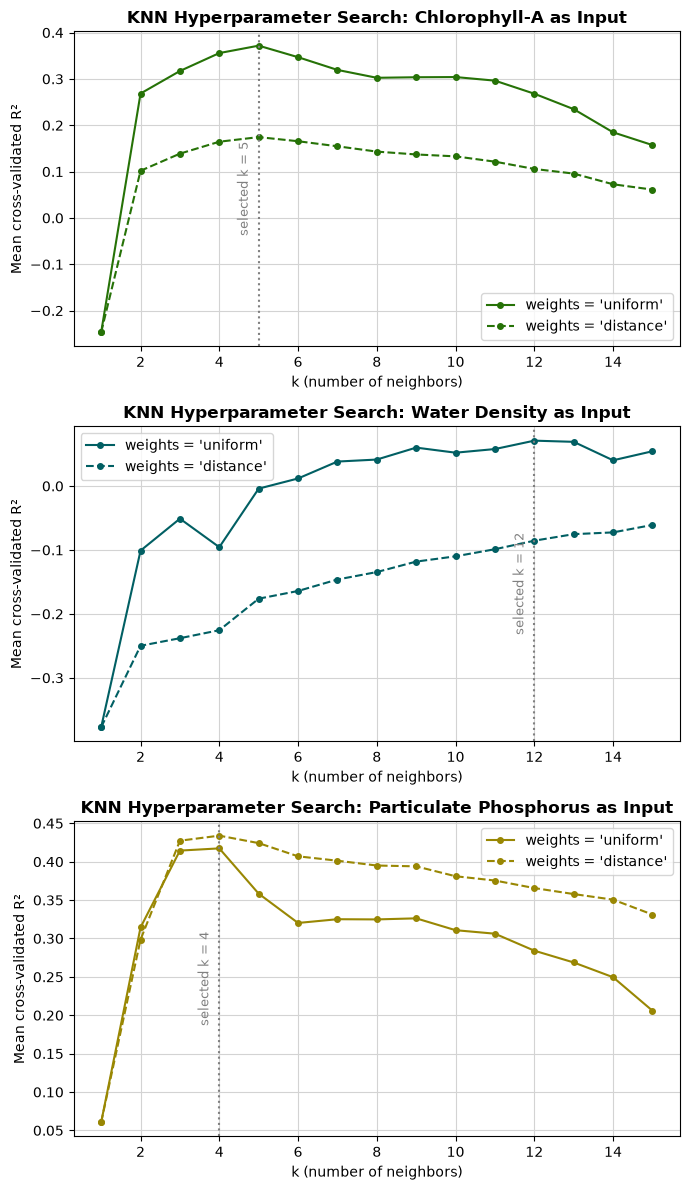

In [39]:
print("Plots: cross-validated R² as a function of k (number of neighbors) for each input variable")

fig, axes = plt.subplots(len(features), 1, figsize=(7,4*len(features)), dpi=100)
for ax, var in zip(axes, features):
    s = fitted[(var, 'KNN')]['search']
    res = pd.DataFrame(s.cv_results_)
    res['k'] = res['param_model__n_neighbors'].astype(int)
    res['cv_r2'] = mse_score_to_r2(res['mean_test_score'])   # convert the MSE-based score to a cross-validated R²

    ax.set_axisbelow(True)
    ax.grid(True, color='lightgray')
    # solid line = uniform weights, dashed line = distance weights
    for weights, style in [('uniform', '-'), ('distance', '--')]:
        sub_res = res[res['param_model__weights'] == weights].sort_values('k')
        ax.plot(sub_res['k'], sub_res['cv_r2'], style, marker='o', markersize=4,
                color=var_colors[var], label=f"weights = '{weights}'")

    # mark the best k
    best_k = s.best_params_['model__n_neighbors']
    ax.axvline(best_k, color='gray', linestyle=':', linewidth=1.5)
    ax.text(best_k - 0.2, 0.5, f'selected k = {best_k}', color='gray', fontsize=9, rotation=90,
            ha='right', va='center', transform=ax.get_xaxis_transform())

    ax.set_xlabel('k (number of neighbors)')
    ax.set_ylabel('Mean cross-validated R²')
    ax.set_title(f"KNN Hyperparameter Search: {alt_name[var]} as Input", fontweight='bold')
    ax.legend(loc='best')
plt.tight_layout()
plt.show()

In [40]:
# How flat is the optimum? List the k values whose score is within 0.05 of the best score
# (with weights fixed at the selected type), plus the scores at a few reference values of k
rows = []
for var in features:
    s = fitted[(var, 'KNN')]['search']
    res = pd.DataFrame(s.cv_results_)
    res['k'] = res['param_model__n_neighbors'].astype(int)
    res['cv_r2'] = mse_score_to_r2(res['mean_test_score'])
    uniform = res[res['param_model__weights'] == 'uniform'].set_index('k')['cv_r2']
    distance = res[res['param_model__weights'] == 'distance'].set_index('k')['cv_r2']
    res = res[res['param_model__weights'] == s.best_params_['model__weights']].set_index('k')['cv_r2']
    near_best = list(res[res >= res.max() - 0.05].index)
    rows.append({'Input': alt_name[var], 'Selected k': s.best_params_['model__n_neighbors'],
                 'Selected weights': s.best_params_['model__weights'],
                 'k values within 0.05 of best R²': ', '.join(str(k) for k in near_best),
                 'CV R² at k=1': res[1], 'CV R² at selected k': res.max(), 'CV R² at k=15': res[15],
                 'Best CV R² (uniform)': uniform.max(), 'Best CV R² (distance)': distance.max()})
print("KNN: how sensitive is the score to k?")
pd.DataFrame(rows).set_index('Input').round(2)

KNN: how sensitive is the score to k?


,Selected k,Selected weights,k values within 0.05 of best R²,CV R² at k=1,CV R² at selected k,CV R² at k=15,Best CV R² (uniform),Best CV R² (distance)
Input,,,,,,,,
Chlorophyll-A,5,uniform,"4, 5, 6",-0.25,0.37,0.16,0.37,0.17
Water Density,12,uniform,"7, 8, 9, 10, 11, 12, 13, 14, 15",-0.38,0.07,0.05,0.07,-0.06
Particulate Phosphorus,4,distance,"3, 4, 5, 6, 7, 8, 9",0.06,0.43,0.33,0.42,0.43


In [41]:
# Why not a very small k? Compare the selected k with k = 2 for Water Density on the training, test, and cross-validated R²
var = 'SIGMA_T'
best = fitted[(var, 'KNN')]['model']
rows = []
for k in [best.named_steps['model'].n_neighbors, 2]:
    m = clone(best).set_params(model__n_neighbors=k).fit(X_train[[var]], y_train)
    rows.append({'k': k, 'Train R²': r2_score(y_train, m.predict(X_train[[var]])),
                 'Test R²': r2_score(y_test, m.predict(X_test[[var]])),
                 'CV R²': cv_r2_score(clone(m), X_train[[var]])})
print(f"KNN with {alt_name[var]} as input: selected k vs. k = 2")
pd.DataFrame(rows).set_index('k').round(2)

KNN with Water Density as input: selected k vs. k = 2


,Train R²,Test R²,CV R²
k,,,
12,0.20,0.34,0.07
2,0.64,0.54,-0.10


--------------------------------------------------------------------------------------

**Why these values of k?** The value of `k` is a tradeoff between flexibility and smoothness (Hastie et al., 2009). With `k = 1`, the model copies the single closest training sample and fits all its noise, and the cross-validated R² (CV R²) is much lower than for any other `k` (-0.25, -0.38, and 0.06 for the three inputs). As `k` increases, the predictions become smoother, and the score rises quickly. For large `k`, the model averages over so many samples (each cross-validation training fold has only about 21 samples) that it flattens the real trend and the score declines again (for example, 0.16 for Chlorophyll-A at `k = 15`).
- **Chlorophyll-A, k = 5:** the score peaks at k = 4-6 and declines gently on both sides. This is close to the common rule of thumb of using about the square root of the number of training samples (√27 ≈ 5).
- **Water Density, k = 12:** The relationship with `KD` is weak and noisy, so the score is poor at small `k` and keeps improving as more neighbors are averaged, leveling off for `k` of 7 to 15. A larger `k` suppresses noise when the signal is weak, so the selected `k` is high, though any `k` from 7 to 15 scores within 0.05 of it.
- **Particulate Phosphorus, k = 4 (distance weights):** The score peaks at k = 3-4, and every k from 3 to 9 scores within 0.05 of the best. The distance-weighted and uniform-weighted models score almost the same (best cross-validated R² of 0.43 vs. 0.42), so the choice of distance weighting is within the noise of the cross-validation. Because distance weighting predicts each training sample almost exactly (training R² = 0.995, see Section 06), a uniform-weighted model would be an equally good (and probably safer) choice here.
- Uniform weights scored better than distance weights for Chlorophyll-A (0.37 vs. 0.17) and Water Density (0.07 vs. -0.06), which is typical for small, noisy data where giving extra weight to the closest neighbors mostly emphasizes noise.

All inputs were standardized before the distances were calculated (it makes no difference for the ranking of neighbors with a single input, but keeps the setup identical to what would be needed with several inputs).

**Why not a very small k for Water Density?** With `k = 2`, the Water Density model scores a higher test R² (0.54) than the selected `k = 12` (0.34), but its cross-validated R² is negative (-0.10 vs. 0.07) and its training R² jumps from 0.20 to 0.64. Averaging only 2 neighbors copies the noise of individual samples, and the higher test R² comes from the particular 10 test samples rather than from a better model, so the cross-validated choice (`k = 12`) is kept.

--------------------------------------------------------------------------------------

### 05.3 Radius Neighbors: How Was the Search Radius Determined?

The radius sets how far away (in the input variable) a training sample can be and still count as a neighbor: a very small radius leaves most predictions with only one or no neighbors (noisy), while a very large radius averages over most of the data (over-smoothed). The radius was determined by testing a range of radii with cross-validation; the results are shown for each input, with the radius converted back to the original units of each input.

Plots: cross-validated R² as a function of the search radius for each input variable


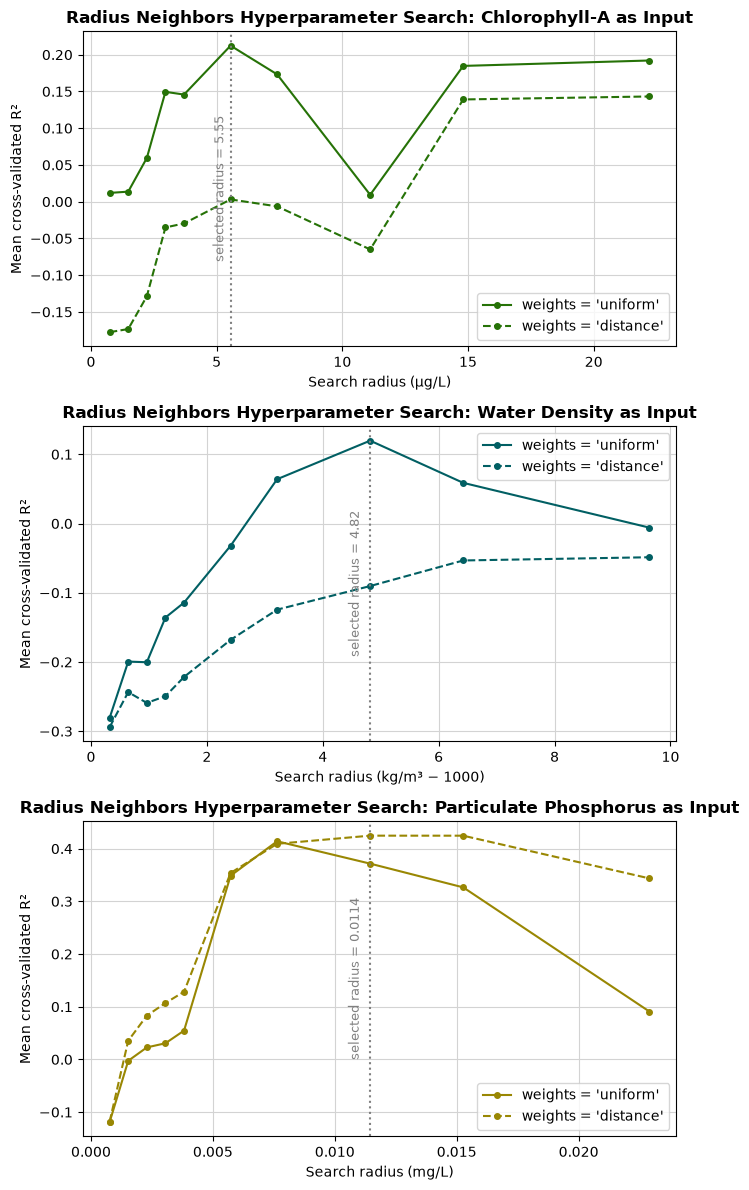

In [42]:
print("Plots: cross-validated R² as a function of the search radius for each input variable")

fig, axes = plt.subplots(len(features), 1, figsize=(7,4*len(features)), dpi=100)
for ax, var in zip(axes, features):
    s = fitted[(var, 'Radius Neighbors')]['search']
    sd = X_train[var].std(ddof=0)                              # standard deviation of the input, to convert the radius to input units
    res = pd.DataFrame(s.cv_results_)
    res['radius'] = res['param_model__radius'].astype(float)
    res['radius_units'] = res['radius'] * sd
    res['cv_r2'] = mse_score_to_r2(res['mean_test_score'])

    ax.set_axisbelow(True)
    ax.grid(True, color='lightgray')
    for weights, style in [('uniform', '-'), ('distance', '--')]:
        sub_res = res[res['param_model__weights'] == weights].sort_values('radius')
        ax.plot(sub_res['radius_units'], sub_res['cv_r2'], style, marker='o', markersize=4,
                color=var_colors[var], label=f"weights = '{weights}'")

    # mark the best radius
    best_r = s.best_params_['model__radius'] * sd
    ax.axvline(best_r, color='gray', linestyle=':', linewidth=1.5)
    ax.text(best_r * 0.97, 0.5, f'selected radius = {best_r:.3g}', color='gray', fontsize=9, rotation=90,
            ha='right', va='center', transform=ax.get_xaxis_transform())

    ax.set_xlabel(f"Search radius ({get_units(var)})")
    ax.set_ylabel('Mean cross-validated R²')
    ax.set_title(f"Radius Neighbors Hyperparameter Search: {alt_name[var]} as Input", fontweight='bold')
    ax.legend(loc='best')
plt.tight_layout()
plt.show()

In [43]:
# Summary of the radius search: selected radius, how flat the optimum is, and how many test samples have no neighbors
rows = []
for var in features:
    s = fitted[(var, 'Radius Neighbors')]['search']
    sd = X_train[var].std(ddof=0)
    res = pd.DataFrame(s.cv_results_)
    res['radius'] = res['param_model__radius'].astype(float)
    res['cv_r2'] = mse_score_to_r2(res['mean_test_score'])
    res = res[res['param_model__weights'] == s.best_params_['model__weights']].set_index('radius')['cv_r2']
    near_best = list(res[res >= res.max() - 0.05].index)

    # number of test samples that have no training samples within the selected radius (they get the training mean)
    pipe = fitted[(var, 'Radius Neighbors')]['model']
    neighbors = pipe.named_steps['model'].radius_neighbors(pipe.named_steps['scale'].transform(X_test[[var]]), return_distance=False)
    n_empty = sum(len(n) == 0 for n in neighbors)

    rows.append({'Input': alt_name[var],
                 'Selected radius (std. devs.)': s.best_params_['model__radius'],
                 f'Selected radius (input units)': f"{s.best_params_['model__radius'] * sd:.3g} {get_units(var)}",
                 'Selected weights': s.best_params_['model__weights'],
                 'Radii within 0.05 of best R² (std. devs.)': ', '.join(str(r) for r in near_best),
                 'CV R² at smallest radius': res.iloc[0], 'CV R² at selected radius': res.max(), 'CV R² at largest radius': res.iloc[-1],
                 'Test samples with no neighbors': f"{n_empty} of {len(X_test)}"})
print("Radius Neighbors: how sensitive is the score to the radius?")
pd.DataFrame(rows).set_index('Input').round(2)

Radius Neighbors: how sensitive is the score to the radius?


,Selected radius (std. devs.),Selected radius (input units),Selected weights,Radii within 0.05 of best R² (std. devs.),CV R² at smallest radius,CV R² at selected radius,CV R² at largest radius,Test samples with no neighbors
Input,,,,,,,,
Chlorophyll-A,0.75,5.55 μg/L,uniform,"0.75, 1.0, 2.0, 3.0",0.01,0.21,0.19,0 of 10
Water Density,1.50,4.82 kg/m³ − 1000,uniform,1.5,-0.28,0.12,-0.01,0 of 10
Particulate Phosphorus,1.50,0.0114 mg/L,distance,"1.0, 1.5, 2.0",-0.12,0.42,0.34,0 of 10


--------------------------------------------------------------------------------------

**How was the search radius determined?** The radius was chosen automatically by testing 10 radii from 0.1 to 3 standard deviations of each input (about 0.8-22 μg/L for Chlorophyll-A, 0.3-9.6 kg/m³ for Water Density, and 0.0008-0.023 mg/L for Particulate Phosphorus) with both weighting types, and keeping the combination with the best cross-validated R². As with `k` in KNN, the radius is a tradeoff between noise and smoothing: with a very small radius most validation samples have few or no training samples nearby (they get the training mean when there is none), and with a very large radius the model averages over most of the data and flattens the trend.
- **Chlorophyll-A, radius = 5.55 μg/L (0.75 standard deviations), uniform weights:** the cross-validated R² is 0.21, and it is nearly flat (within 0.05 of the best) at radii of 0.75, 1, 2, and 3 standard deviations, with a dip in between (a sign that the score is noisy and that the choice among these radii is not meaningful). The smallest radius scores only 0.01.
- **Water Density, radius = 4.82 kg/m³ (1.5 standard deviations), uniform weights:** this is the only radius within 0.05 of the best score (0.12). The scores are lower for smaller radii (-0.28 at the smallest) and for larger ones (-0.01 at the largest), so the weak relationship needs a wide window of about 5 kg/m³ to average out the noise.
- **Particulate Phosphorus, radius = 0.0114 mg/L (1.5 standard deviations), distance weights:** radii of 1 to 2 standard deviations are all within 0.05 of the best (0.42). The score is poor for the smallest radius (-0.12) and falls for the largest (0.34). As with KNN, the distance weighting makes the model memorize the training samples (training R² = 0.995).
- At the selected radii, all 10 test samples had at least one training sample within the radius, so none of the test predictions relied on the fallback to the training mean.

--------------------------------------------------------------------------------------

--------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------

### SECTION 05 SUMMARY: Choosing the Hyperparameters

**Selected hyperparameters and findings of this section:**

| Input | Polynomial Regression | KNN (non-linear) | Radius Neighbors |
|---|---|---|---|
| Chlorophyll-A | degree = 1 | k = 5, uniform weights | radius = 0.75 std. devs. (5.55 μg/L), uniform weights |
| Water Density | degree = 1 | k = 12, uniform weights | radius = 1.5 std. devs. (4.82 kg/m³), uniform weights |
| Particulate Phosphorus | degree = 1 | k = 4, distance weights | radius = 1.5 std. devs. (0.0114 mg/L), distance weights |

- All hyperparameters were selected automatically by cross-validated grid search on the training data, so the notebook runs without user input, and the test set was not used to make any choices.
- **Polynomial regression:** degree 1 (a straight line) scored best for every input. Higher degrees fit the training data more closely but make extreme, physically impossible predictions away from the bulk of the data (e.g., a `KD` of -5.26 m⁻¹ at degree 4 for Chlorophyll-A), so their cross-validated R² is strongly negative.
- **KNN:** a small `k` overfits the noise and a large `k` over-smooths. The best `k` was 4-5 for the two inputs with a clear signal and larger for the weak input (Water Density); `k = 2` for Water Density looked better on the test set by chance but scored worse in cross-validation.
- **Radius Neighbors:** the radius shows the same tradeoff: too small and the predictions are noisy (or fall back to the mean), too large and the trend is flattened. The best radii were about 1 standard deviation of the input (0.75 to 1.5 standard deviations).
- The distance weighting selected for Particulate Phosphorus (in both neighbor models) is not clearly better than uniform weights and leads to models that memorize the training samples.
- In several cases, a hyperparameter value that scored better on the single test set (degree 4 for Chlorophyll-A, `k = 2` for Water Density) was worse in cross-validation, which shows why hyperparameters should not be chosen with the test set.

--------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------

--------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------

## 06) Model Evaluation & Visualization

All nine fitted models (3 techniques x 3 inputs) are evaluated here. **R²** (the coefficient of determination; 1 is a perfect prediction, 0 is no better than always predicting the mean) is shown on every plot, for the training data, the held-out test data, and cross-validation on the training data. Because the test set is very small, the cross-validated R² is a more stable estimate. The mean absolute error (MAE, in m⁻¹, the average size of the prediction error) is also reported.

--------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------

### 06.1 Scores for All Models

Score every fitted model on the training and test sets and collect the results in a table.

In [44]:
# Score each of the 9 models on the training and test sets and collect the results
rows = []
for var in features:
    for tech in techniques:
        f = fitted[(var, tech)]
        pred_train = f['model'].predict(X_train[[var]])
        pred_test  = f['model'].predict(X_test[[var]])
        rows.append({'Input': alt_name[var], 'Model': tech,
                     'Train R²': r2_score(y_train, pred_train),
                     'CV R² (train)': f['cv_r2'],
                     'Test R²': r2_score(y_test, pred_test),
                     'Test RMSE (m⁻¹)': np.sqrt(mean_squared_error(y_test, pred_test)),
                     'Test MAE (m⁻¹)': mean_absolute_error(y_test, pred_test)})
results_df = pd.DataFrame(rows)

print("Scores of all models:")
results_df.set_index(['Input', 'Model']).round(3)

Scores of all models:


Train R²  CV R² (train)  Test R²  Test RMSE (m⁻¹)  Test MAE (m⁻¹)
Input                  Model                                                                                   
Chlorophyll-A          Polynomial Regression     0.609          0.544    0.057            0.194           0.168
                       KNN                       0.562          0.372    0.139            0.186           0.146
                       Radius Neighbors          0.632          0.212    0.121            0.187           0.153
Water Density          Polynomial Regression     0.271          0.153    0.528            0.137           0.110
                       KNN                       0.203          0.071    0.336            0.163           0.127
                       Radius Neighbors          0.235          0.120    0.367            0.159           0.118
Particulate Phosphorus Polynomial Regression     0.585          0.505    0.023            0.198           0.164
                       KNN                       0.995          0.434    0.063            0.194           0.142
                       Radius Neighbors          0.995          0.425   -0.045            0.204           0.158

In [45]:
# For reference: the baseline (always predict the mean KD) scores
print("Baseline model scores for comparison:")
print({k: round(float(v), 3) for k, v in baseline_scores.items()})

# Test R² of every model in a compact table (rows = input variable, columns = model)
print("\nTest R² (rows = input variable, columns = model):")
results_df.pivot(index='Input', columns='Model', values='Test R²')[techniques].round(3)

Baseline model scores for comparison:
{'Train R²': 0.0, 'CV R² (train)': -0.082, 'Test R²': -0.007}

Test R² (rows = input variable, columns = model):


Model,Polynomial Regression,KNN,Radius Neighbors
Input,,,
Chlorophyll-A,0.057,0.139,0.121
Particulate Phosphorus,0.023,0.063,-0.045
Water Density,0.528,0.336,0.367


### 06.2 Actual vs. Predicted Plots

For each of the three models, scatter plots of the actual `KD` vs. the `KD` predicted by the model (one plot for each input variable). A perfect model would put every point on the dashed 1:1 line. The R² scores are displayed on every plot.

Plots: Polynomial Regression, actual vs. predicted KD for each input variable


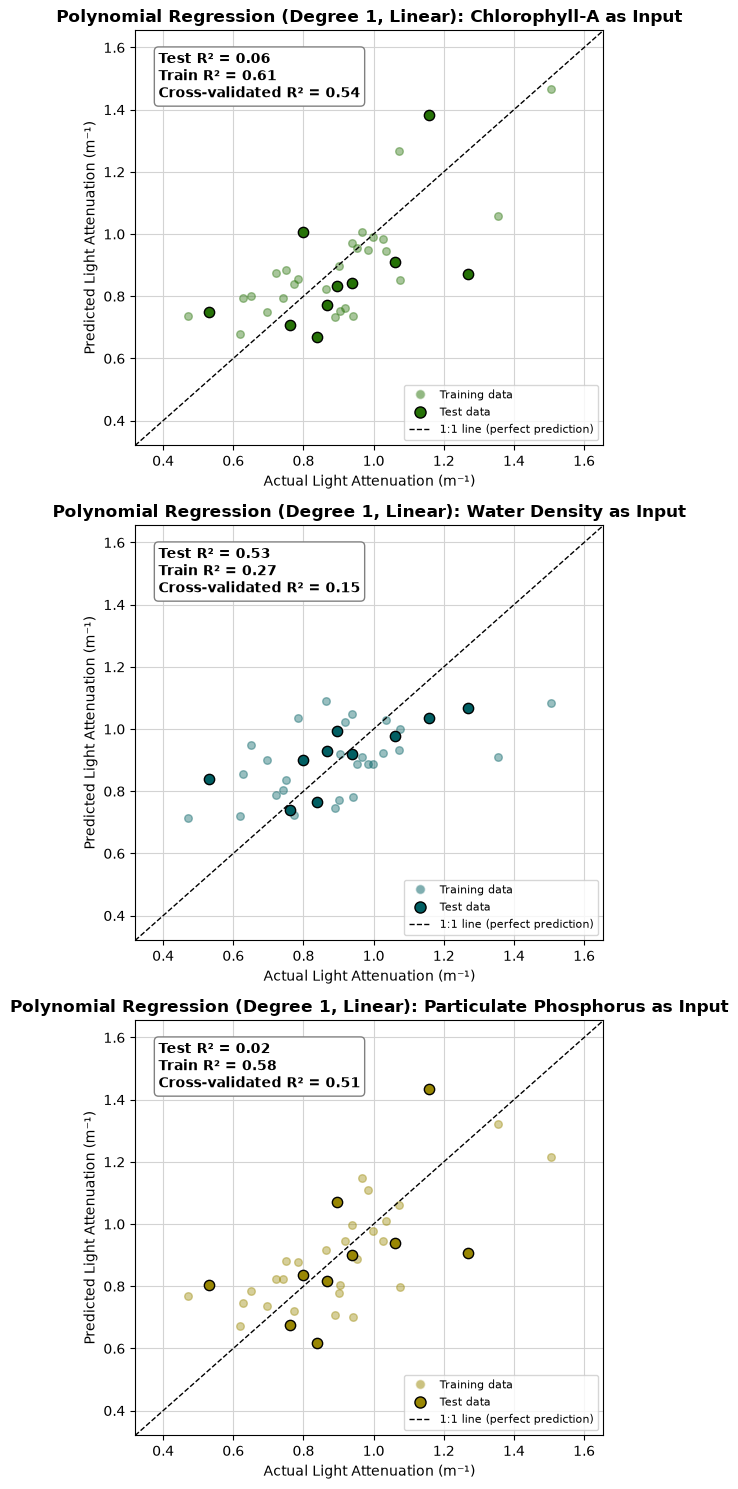

In [46]:
# A reusable function: draws the actual vs. predicted plots for one technique (one stacked plot per input variable)
lims = [y.min() - 0.15, y.max() + 0.15]   # same axis limits on every plot so they can be compared directly

def plot_actual_vs_predicted(tech):
    fig, axes = plt.subplots(len(features), 1, figsize=(5.5, 5*len(features)), dpi=100)
    for ax, var in zip(axes, features):
        f = fitted[(var, tech)]
        pred_train = f['model'].predict(X_train[[var]])
        pred_test  = f['model'].predict(X_test[[var]])
        color = var_colors[var]

        ax.set_axisbelow(True)
        ax.grid(True, color='lightgray')
        ax.scatter(y_train, pred_train, color=color, alpha=0.4, s=30)               # training data (faint)
        ax.scatter(y_test,  pred_test,  color=color, edgecolor='black', s=55)       # test data (bold, outlined)
        ax.plot(lims, lims, 'k--', linewidth=1)                                     # 1:1 line
        ax.set_xlim(lims); ax.set_ylim(lims)

        # R² displayed on the plot
        r2_train = r2_score(y_train, pred_train)
        r2_test  = r2_score(y_test, pred_test)
        ax.text(0.05, 0.95, f"Test R² = {r2_test:.2f}\nTrain R² = {r2_train:.2f}\nCross-validated R² = {f['cv_r2']:.2f}",
                transform=ax.transAxes, ha='left', va='top', fontsize=10, fontweight='bold',
                bbox=dict(boxstyle='round', facecolor='white', edgecolor='gray'))

        ax.set_xlabel('Actual ' + axis_label(target))
        ax.set_ylabel('Predicted ' + axis_label(target))
        ax.set_title(f"{model_title(var, tech)}: {alt_name[var]} as Input", fontweight='bold')
        handles = [Line2D([0], [0], marker='o', color='w', markerfacecolor=color, alpha=0.5, markersize=7, label='Training data'),
                   Line2D([0], [0], marker='o', color='w', markerfacecolor=color, markeredgecolor='black', markersize=8, label='Test data'),
                   Line2D([0], [0], color='k', linestyle='--', linewidth=1, label='1:1 line (perfect prediction)')]
        ax.legend(handles=handles, loc='lower right', fontsize=8)
    plt.tight_layout()
    plt.show()

print("Plots: Polynomial Regression, actual vs. predicted KD for each input variable")
plot_actual_vs_predicted('Polynomial Regression')

Plots: KNN, actual vs. predicted KD for each input variable


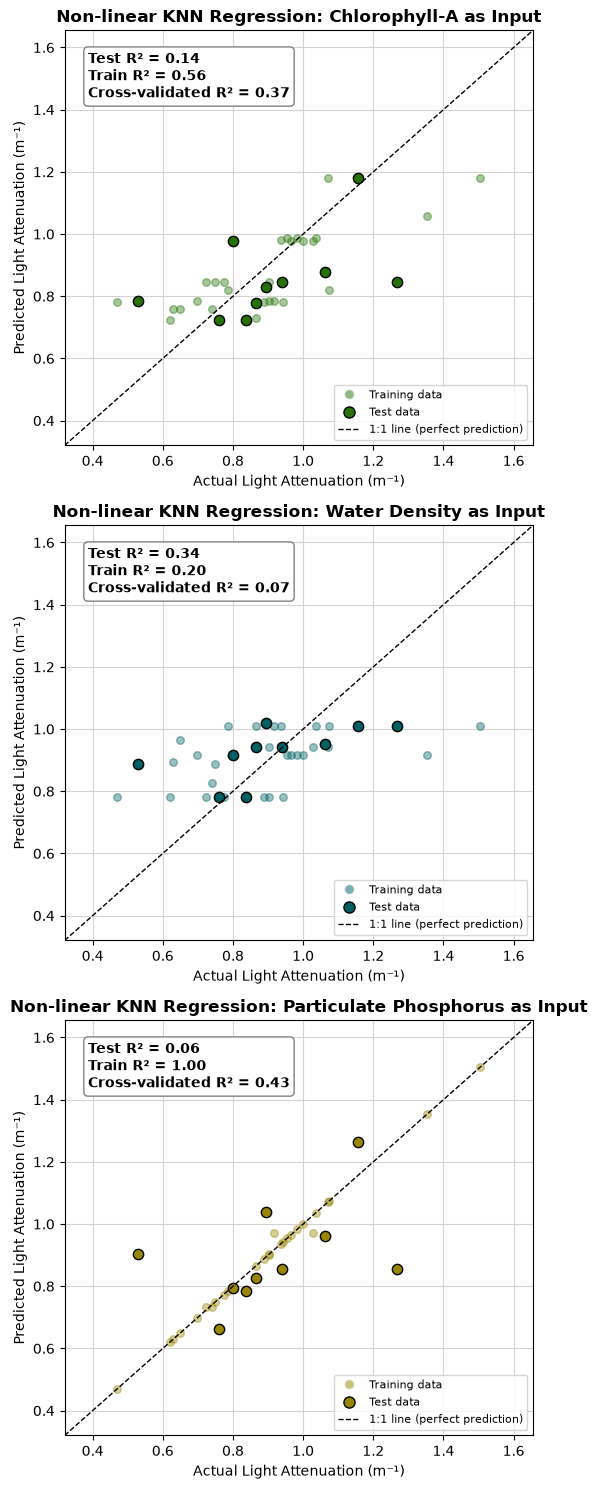

In [47]:
print("Plots: KNN, actual vs. predicted KD for each input variable")
plot_actual_vs_predicted('KNN')

Plots: Radius Neighbors, actual vs. predicted KD for each input variable


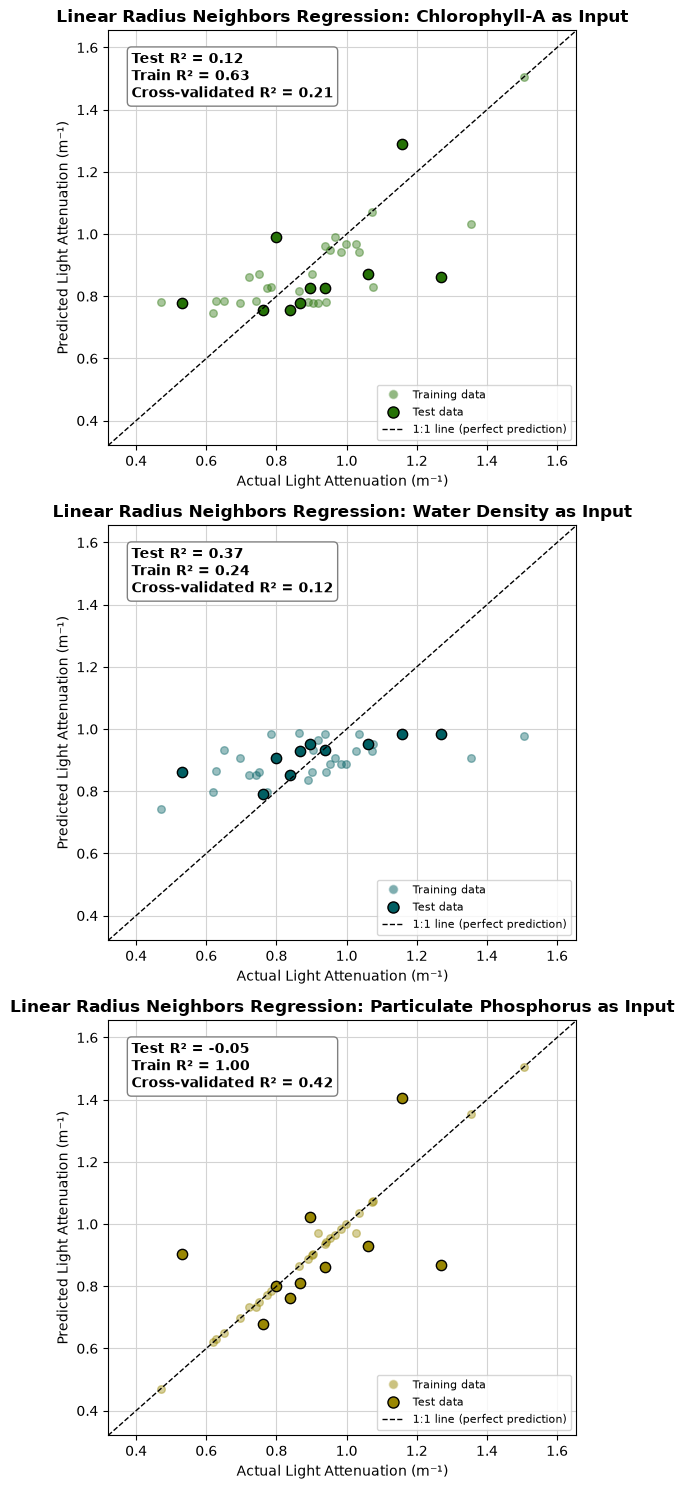

In [48]:
print("Plots: Radius Neighbors, actual vs. predicted KD for each input variable")
plot_actual_vs_predicted('Radius Neighbors')

--------------------------------------------------------------------------------------

**Reading the plots:** points close to the dashed 1:1 line are well predicted. Several patterns appear in all nine plots:
- Predictions are compressed toward the middle of the data: the lowest `KD` values are over-predicted, and the highest `KD` values are under-predicted. This is normal for models with modest skill.
- **The test R² and the cross-validated R² often disagree.** For example, the polynomial (degree 1) regression with Chlorophyll-A has a test R² of only 0.06 but a cross-validated R² of 0.54, and the polynomial (degree 1) regression with Water Density has the opposite pattern (test R² of 0.53, cross-validated R² of 0.15). The reason is the small test set (10 samples): just one or two poorly predicted samples can change the test R² a lot. Therefore, **the test R² of a single split should not be over-interpreted**, and the cross-validated and repeated-split scores in 06.4 are more reliable.
- The KNN and Radius Neighbors models with Particulate Phosphorus have a training R² of 0.995 (printed as 1.00 in 06.3) because they use distance weighting, in which each training sample is its own nearest neighbor (at distance zero) and so is predicted almost exactly. This suggests memorization of the training data rather than a good model, and their test R² is only 0.06 (KNN) and -0.05 (Radius Neighbors).

--------------------------------------------------------------------------------------

### 06.3 Data and Fitted Model Plots

The raw data points overlain with the line (or curve) each fitted model predicts across the range of each input variable. Before each plot, the information specific to the model (the fitted equation for polynomial regression, the selected hyperparameters for KNN and Radius Neighbors) is printed, followed by the R² score of the training data, the R² score of the test data, the cross-validated R² score (training data), and the mean absolute error (MAE) of the test data.

In [49]:
# A reusable function: prints the model-specific information and the scores, then plots the raw data with the model line
def show_model_fit(var, tech):
    f = fitted[(var, tech)]
    model = f['model']
    pred_train = model.predict(X_train[[var]])
    pred_test  = model.predict(X_test[[var]])
    r2_train = r2_score(y_train, pred_train)
    r2_test  = r2_score(y_test, pred_test)
    mae      = mean_absolute_error(y_test, pred_test)

    # 1) Information specific to each model
    print(f"{model_title(var, tech)}: {alt_name[var]} as input")
    if tech == 'Polynomial Regression':
        print(f"Selected degree: {model.named_steps['poly'].degree}")
        print(f"Model equation (KD in m⁻¹, {alt_name[var]} in {get_units(var)}): {poly_equation(var)}")
    elif tech == 'KNN':
        knn = model.named_steps['model']
        print(f"Selected hyperparameters: k = {knn.n_neighbors}, weights = '{knn.weights}'")
    else:
        rnr = model.named_steps['model']
        radius_units = rnr.radius * model.named_steps['scale'].scale_[0]
        neighbors = rnr.radius_neighbors(model.named_steps['scale'].transform(X_test[[var]]), return_distance=False)
        n_empty = sum(len(n) == 0 for n in neighbors)
        print(f"Selected hyperparameters: radius = {rnr.radius} std. devs. ({radius_units:.3g} {get_units(var)}), weights = '{rnr.weights}'")
        print(f"Test samples with no neighbors within the radius: {n_empty} of {len(X_test)}")

    # 2) Scores (same format as the class regression examples)
    print(f"R-squared score (training data): {r2_train:.2f}")
    print(f"R-squared score (test data): {r2_test:.2f}")
    print(f"Cross-validated R-squared score (training data): {f['cv_r2']:.2f}")
    print(f"Mean absolute error (MAE, test data): {mae:.3f} m⁻¹")

    # 3) Plot: raw data points overlain with the model line
    grid = pd.DataFrame({var: np.linspace(X[var].min(), X[var].max(), 400)})
    fig, ax = plt.subplots(figsize=(7,4.5), dpi=100)
    ax.set_axisbelow(True)
    ax.grid(True, color='lightgray')
    ax.scatter(X_train[var], y_train, color=var_colors[var], alpha=0.4, s=30, label='Training data')
    ax.scatter(X_test[var],  y_test,  color=var_colors[var], edgecolor='black', s=55, label='Test data')
    ax.plot(grid[var], model.predict(grid), color=model_colors[tech], linewidth=2.2, label=f"{model_title(var, tech)} line")
    ax.text(0.97, 0.05, f"Train R² = {r2_train:.2f}\nTest R² = {r2_test:.2f}\nCross-validated R² = {f['cv_r2']:.2f}\nTest MAE = {mae:.3f} m⁻¹",
            transform=ax.transAxes, ha='right', va='bottom', fontsize=9, fontweight='bold',
            bbox=dict(boxstyle='round', facecolor='white', edgecolor='gray'))
    ax.set_xlabel(axis_label(var))
    ax.set_ylabel(axis_label(target))
    ax.set_title(f"{model_title(var, tech)}: {alt_name[target]} vs. {alt_name[var]}", fontweight='bold')
    ax.legend(loc='upper left', fontsize=8)
    plt.tight_layout()
    plt.show()
    print()

Polynomial Regression (Degree 1, Linear): Chlorophyll-A as input
Selected degree: 1
Model equation (KD in m⁻¹, Chlorophyll-A in μg/L): Light Attenuation = 0.5904 + 0.02263 × Chlorophyll-A
R-squared score (training data): 0.61
R-squared score (test data): 0.06
Cross-validated R-squared score (training data): 0.54
Mean absolute error (MAE, test data): 0.168 m⁻¹


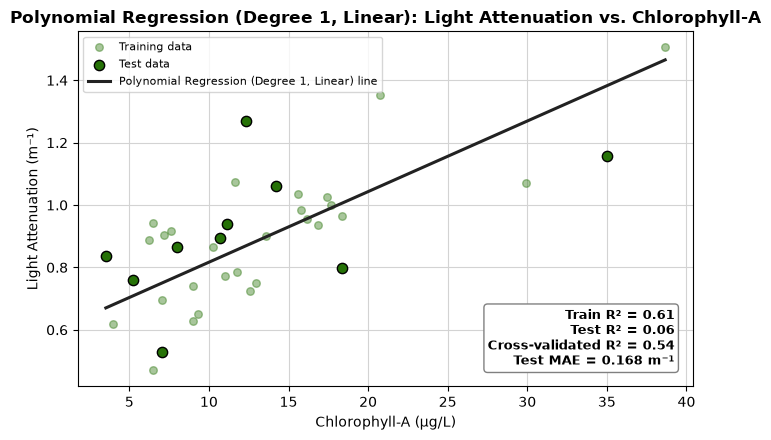


Polynomial Regression (Degree 1, Linear): Water Density as input
Selected degree: 1
Model equation (KD in m⁻¹, Water Density in kg/m³ − 1000): Light Attenuation = 1.155 − 0.03478 × Water Density
R-squared score (training data): 0.27
R-squared score (test data): 0.53
Cross-validated R-squared score (training data): 0.15
Mean absolute error (MAE, test data): 0.110 m⁻¹


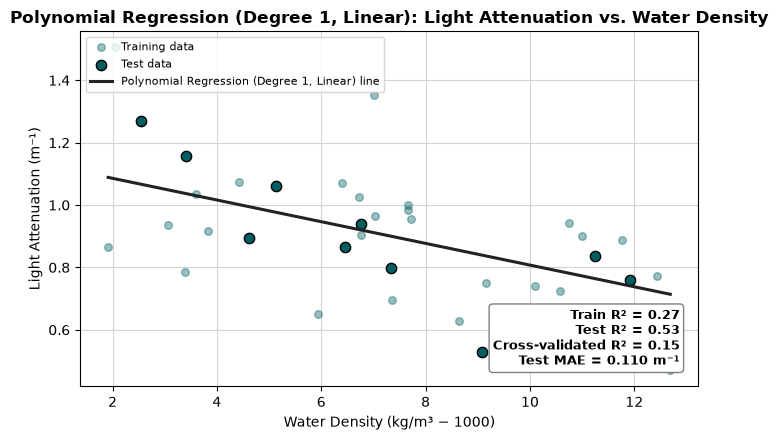


Polynomial Regression (Degree 1, Linear): Particulate Phosphorus as input
Selected degree: 1
Model equation (KD in m⁻¹, Particulate Phosphorus in mg/L): Light Attenuation = 0.4821 + 21.5 × Particulate Phosphorus
R-squared score (training data): 0.58
R-squared score (test data): 0.02
Cross-validated R-squared score (training data): 0.51
Mean absolute error (MAE, test data): 0.164 m⁻¹


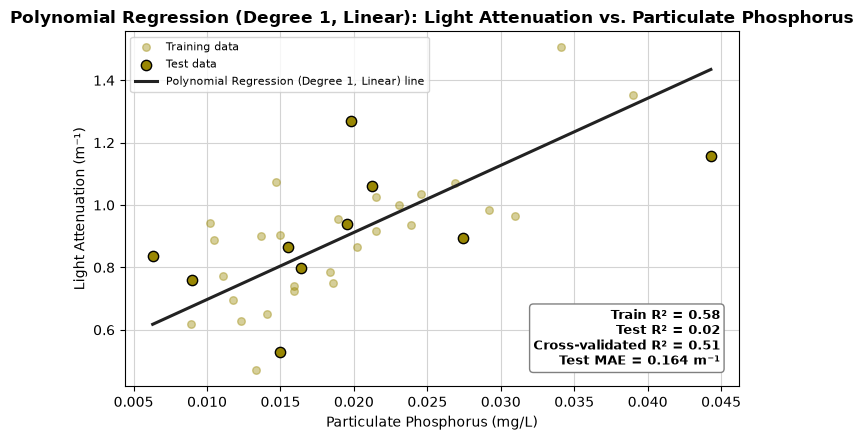

In [50]:
# Polynomial Regression: data and fitted line for each input variable
for var in features:
    show_model_fit(var, 'Polynomial Regression')

Non-linear KNN Regression: Chlorophyll-A as input
Selected hyperparameters: k = 5, weights = 'uniform'
R-squared score (training data): 0.56
R-squared score (test data): 0.14
Cross-validated R-squared score (training data): 0.37
Mean absolute error (MAE, test data): 0.146 m⁻¹


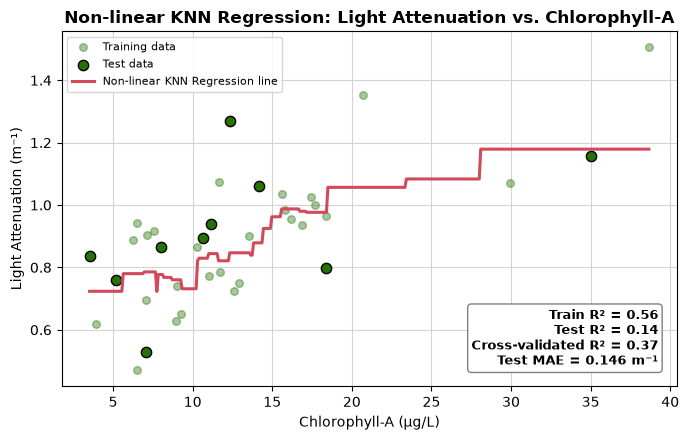


Non-linear KNN Regression: Water Density as input
Selected hyperparameters: k = 12, weights = 'uniform'
R-squared score (training data): 0.20
R-squared score (test data): 0.34
Cross-validated R-squared score (training data): 0.07
Mean absolute error (MAE, test data): 0.127 m⁻¹


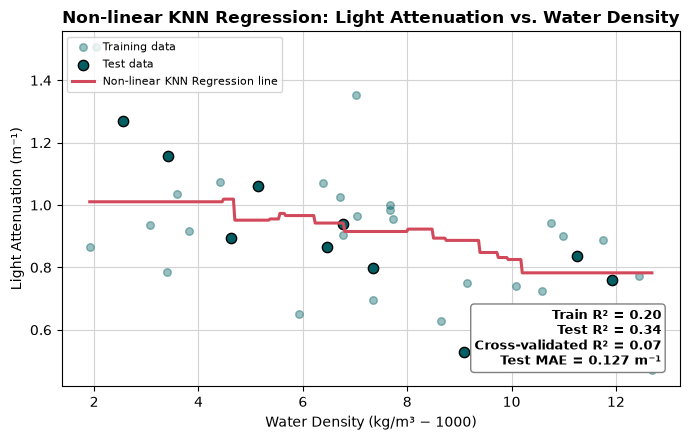


Non-linear KNN Regression: Particulate Phosphorus as input
Selected hyperparameters: k = 4, weights = 'distance'
R-squared score (training data): 1.00
R-squared score (test data): 0.06
Cross-validated R-squared score (training data): 0.43
Mean absolute error (MAE, test data): 0.142 m⁻¹


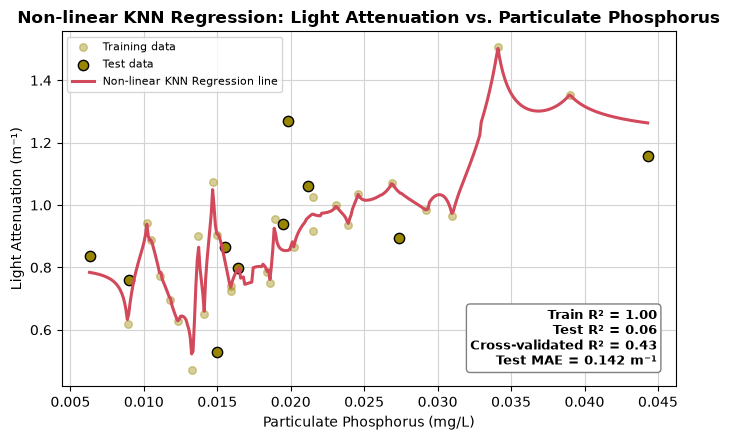

In [51]:
# KNN: data and fitted model line for each input variable
for var in features:
    show_model_fit(var, 'KNN')

Linear Radius Neighbors Regression: Chlorophyll-A as input
Selected hyperparameters: radius = 0.75 std. devs. (5.55 μg/L), weights = 'uniform'
Test samples with no neighbors within the radius: 0 of 10
R-squared score (training data): 0.63
R-squared score (test data): 0.12
Cross-validated R-squared score (training data): 0.21
Mean absolute error (MAE, test data): 0.153 m⁻¹


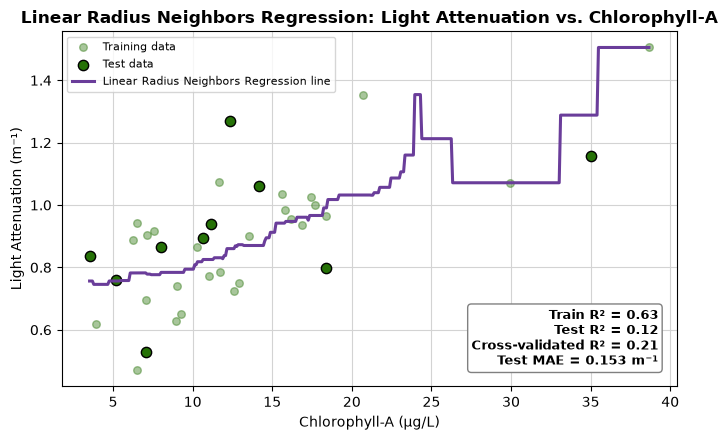


Linear Radius Neighbors Regression: Water Density as input
Selected hyperparameters: radius = 1.5 std. devs. (4.82 kg/m³ − 1000), weights = 'uniform'
Test samples with no neighbors within the radius: 0 of 10
R-squared score (training data): 0.24
R-squared score (test data): 0.37
Cross-validated R-squared score (training data): 0.12
Mean absolute error (MAE, test data): 0.118 m⁻¹


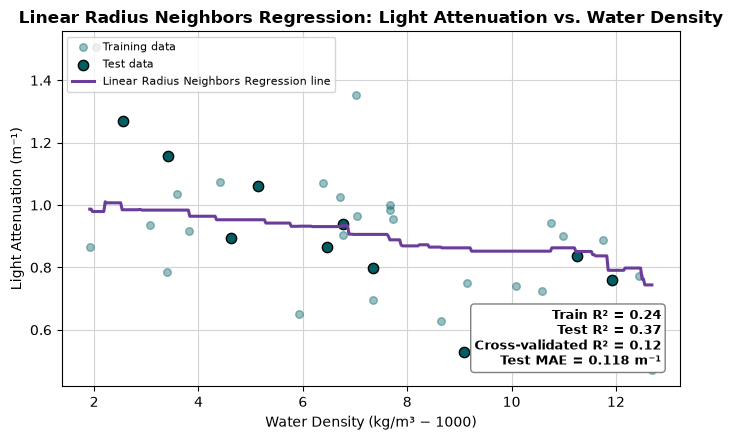


Linear Radius Neighbors Regression: Particulate Phosphorus as input
Selected hyperparameters: radius = 1.5 std. devs. (0.0114 mg/L), weights = 'distance'
Test samples with no neighbors within the radius: 0 of 10
R-squared score (training data): 1.00
R-squared score (test data): -0.05
Cross-validated R-squared score (training data): 0.42
Mean absolute error (MAE, test data): 0.158 m⁻¹


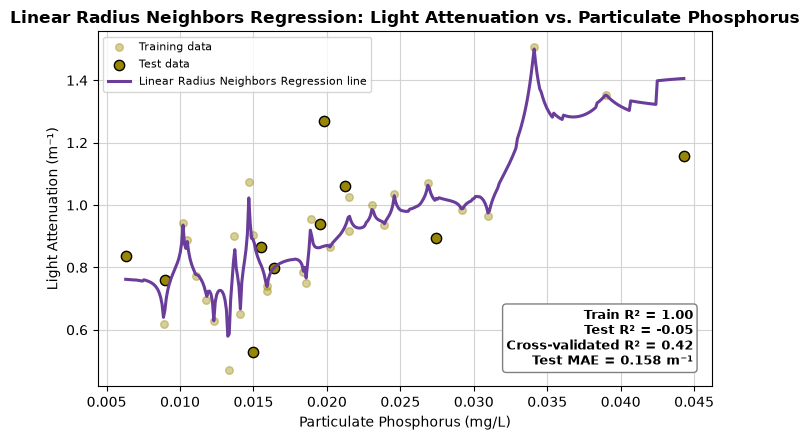

In [52]:
# Radius Neighbors: data and fitted model line for each input variable
for var in features:
    show_model_fit(var, 'Radius Neighbors')

--------------------------------------------------------------------------------------

The plots of the data with the model lines show that:
- **Polynomial regression (degree 1)** gives a straight line through the data for each input (the equations are printed above each plot). Its test MAE is 0.168 m⁻¹ for Chlorophyll-A, 0.110 m⁻¹ for Water Density, and 0.164 m⁻¹ for Particulate Phosphorus.
- **KNN** follows the same upward trend for Chlorophyll-A as a staircase (test MAE of 0.146 m⁻¹) that flattens above about 20-28 μg/L, but this part of the line is based on only ~3 samples with high chlorophyll. For Water Density it is a noisier staircase around the line (0.127 m⁻¹).
- **Radius Neighbors** is similar to KNN but jumps in steps (at high chlorophyll, with very few samples, it jumps up and down between 1.07 and 1.5 m⁻¹, which is noise rather than a pattern). Its test MAE is 0.153 m⁻¹ for Chlorophyll-A and 0.118 m⁻¹ for Water Density.
- **For Particulate Phosphorus**, both the KNN and Radius Neighbors lines (which use distance weighting) are very spiky: they bend to pass through individual training points, which is overfitting (test MAE of 0.142 and 0.158 m⁻¹).
- The test MAE values are all fairly close to each other (0.11 to 0.17 m⁻¹, compared with a typical `KD` of about 0.9 m⁻¹), i.e., the typical prediction error is about 12-19% of the average `KD` regardless of the model. The model that is best on test MAE differs by input (KNN for Chlorophyll-A and Particulate Phosphorus; polynomial (degree 1) regression for Water Density), which, again, mostly reflects the small test set.

**For all three inputs the relationship is well described by a straight line**, and the more flexible models (the non-linear KNN and the Radius Neighbors models) do not follow a different, clearly more accurate shape; they only add noise. With only ~27 training samples there is not enough data to detect any real curvature.

--------------------------------------------------------------------------------------

### 06.4 Model Comparison and Robustness

Compare the nine models side by side and check how much the results depend on the particular train/test split.

Bar charts: R² of every model for each input variable (dashed line = baseline, always predicting the mean)


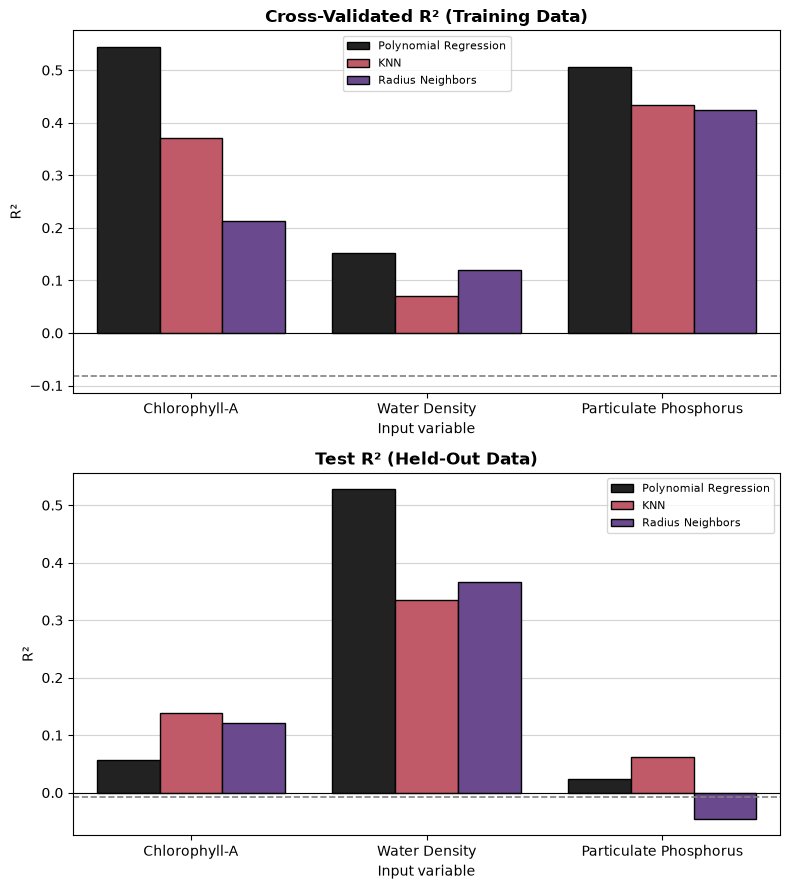

In [53]:
print("Bar charts: R² of every model for each input variable (dashed line = baseline, always predicting the mean)")

fig, axes = plt.subplots(2, 1, figsize=(8,9), dpi=100)
for ax, col, title in zip(axes, ['CV R² (train)', 'Test R²'],
                          ['Cross-Validated R² (Training Data)', 'Test R² (Held-Out Data)']):
    ax.set_axisbelow(True)
    ax.grid(True, color='lightgray', axis='y')
    sns.barplot(data=results_df, x='Input', y=col, hue='Model', hue_order=techniques,
                palette=model_colors, edgecolor='black', ax=ax)
    ax.axhline(0, color='black', linewidth=0.8)
    ax.axhline(baseline_scores[col], color='gray', linestyle='--', linewidth=1.2)
    ax.set_xlabel('Input variable')
    ax.set_ylabel('R²')
    ax.set_title(title, fontweight='bold')
    ax.legend(title=None, fontsize=8)
plt.tight_layout()
plt.show()

#### How much does the result depend on the particular train/test split?
With only 10 test samples, the test R² depends heavily on which samples happened to land in the test set (Roberts et al., 2017). To check this, the following cell repeats the 75/25 split 100 times (different random shuffles), refits each of the nine models with the hyperparameters chosen above, and records the test R² each time. (Caveat: the hyperparameters were tuned on one training set, so this slightly favors the tuned models; it is meant to show the spread, not to give a perfectly unbiased score.)

Boxplots: test R² over 100 random train/test splits (hyperparameters fixed at the tuned values)


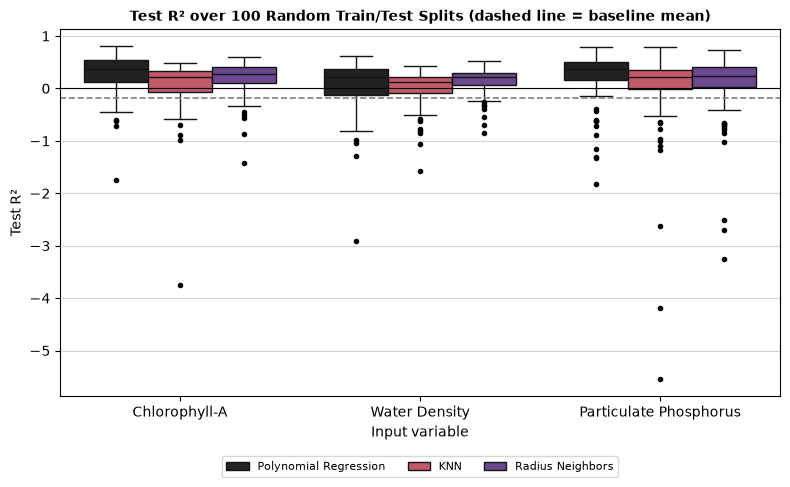

In [54]:
print("Boxplots: test R² over 100 random train/test splits (hyperparameters fixed at the tuned values)")

split_rows = []
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    for seed in range(100):
        Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=seed)
        for var in features:
            for tech in techniques:
                m = clone(fitted[(var, tech)]['model']).fit(Xtr[[var]], ytr)
                split_rows.append({'Input': alt_name[var], 'Model': tech, 'Test R²': r2_score(yte, m.predict(Xte[[var]]))})
        # baseline for reference
        split_rows.append({'Input': 'Baseline', 'Model': 'Baseline',
                           'Test R²': r2_score(yte, DummyRegressor().fit(Xtr, ytr).predict(Xte))})
split_df = pd.DataFrame(split_rows)
baseline_split_mean = split_df[split_df['Model'] == 'Baseline']['Test R²'].mean()
split_df = split_df[split_df['Model'] != 'Baseline']

fig, ax = plt.subplots(figsize=(8,5), dpi=100)
ax.set_axisbelow(True)
ax.grid(True, color='lightgray', axis='y')
sns.boxplot(data=split_df, x='Input', y='Test R²', hue='Model', hue_order=techniques, palette=model_colors,
            flierprops=dict(marker='o', markerfacecolor='black', markeredgecolor='black', markersize=3), ax=ax)
ax.axhline(0, color='black', linewidth=0.8)
ax.axhline(baseline_split_mean, color='gray', linestyle='--', linewidth=1.2)
ax.set_xlabel('Input variable')
ax.set_ylabel('Test R²')
ax.set_title('Test R² over 100 Random Train/Test Splits (dashed line = baseline mean)', fontweight='bold', fontsize=10)
ax.legend(title=None, fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=3)
plt.tight_layout()
plt.show()

In [55]:
# Summary of the 100-split experiment: mean, standard deviation, and median of the test R²
print(f"Baseline (always predict the mean): mean test R² over the 100 splits = {baseline_split_mean:.2f}")
print("\nTest R² over 100 random splits (mean / std / median):")
split_summary = (split_df.groupby(['Input', 'Model'])['Test R²'].agg(['mean', 'std', 'median']).round(2)
                         .reindex([alt_name[v] for v in features], level=0).reindex(techniques, level=1))
split_summary

Baseline (always predict the mean): mean test R² over the 100 splits = -0.17

Test R² over 100 random splits (mean / std / median):


mean   std  median
Input                  Model                                    
Chlorophyll-A          Polynomial Regression  0.29  0.40    0.37
                       KNN                    0.07  0.51    0.23
                       Radius Neighbors       0.21  0.32    0.28
Water Density          Polynomial Regression  0.07  0.47    0.21
                       KNN                    0.01  0.34    0.11
                       Radius Neighbors       0.15  0.24    0.22
Particulate Phosphorus Polynomial Regression  0.23  0.46    0.36
                       KNN                    0.01  0.85    0.22
                       Radius Neighbors       0.07  0.63    0.23

--------------------------------------------------------------------------------------

- **Which inputs work best?** Chlorophyll-A and Particulate Phosphorus are clearly better inputs than Water Density. The cross-validated R² of the polynomial (degree 1) regressions is 0.54 and 0.51, compared with 0.15 for Water Density, and the median test R² over the 100 random splits is 0.37 and 0.36, compared with 0.21. Chlorophyll-A and Particulate Phosphorus perform about the same as each other.
- **Which models work best?** The polynomial (degree 1) regression is the best or tied for the best model for Chlorophyll-A and Particulate Phosphorus in cross-validated R² (0.54 vs. 0.37 for KNN and 0.21 for Radius Neighbors with Chlorophyll-A, and 0.51 vs. 0.43 and 0.42 with Particulate Phosphorus), and for Water Density it is also the best (0.15 vs. 0.07 and 0.12). The KNN and Radius Neighbors models are usually a bit worse, and they have no benefit because the relationships are linear.
- **How much does the split matter?** The test R² varies a lot from split to split (standard deviations of 0.24 to 0.85), and for some splits it is below the baseline. This is why the single-split test R² values should not be over-interpreted (as seen in 06.2). Averaged over 100 splits, the polynomial (degree 1) regressions with Chlorophyll-A or Particulate Phosphorus have a mean test R² of 0.29 and 0.23, well above the baseline's mean of -0.17. The distance-weighted KNN and Radius Neighbors models with Particulate Phosphorus are the most variable (standard deviations of 0.85 and 0.63), because they memorize the training samples and make very large errors on some test samples. Radius Neighbors is the most stable of the three techniques for Water Density (standard deviation of 0.24) and has the highest mean test R² for that input (0.15 vs. 0.07 for the polynomial regression), but with such a weak relationship all three techniques score low.
- **Overall:** the best single-variable models are the polynomial (degree 1, i.e., straight-line) regressions with Chlorophyll-A or Particulate Phosphorus (cross-validated R² of about 0.5), which is much better than no skill but leaves a large amount of unexplained variability.

--------------------------------------------------------------------------------------

--------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------

### SECTION 06 SUMMARY: Model Performance

**Findings of this section:**
- All nine models were evaluated with R² on the training data, the held-out test data, and cross-validation, and each is shown in an actual-vs-predicted plot and in a plot of the data with the model line. For each model, the model-specific information (the fitted equation or the selected hyperparameters), the training, test, and cross-validated R², and the MAE are printed before its plot.
- **Chlorophyll-A and Particulate Phosphorus** were the best single predictors of `KD` (cross-validated R² of 0.54 and 0.51 for the polynomial (degree 1) regressions), and **Water Density** was clearly weaker (0.07 to 0.15 for all three techniques).
- **The polynomial regression (degree 1, a straight line) performed best or about the same as the neighbor-based models for every input**, as expected from the linear relationships found in Section 04. The KNN and Radius Neighbors models were more variable, and the distance-weighted models for Particulate Phosphorus memorized the training data.
- The test R² of the single 75/25 split is **unreliable** because of the small test set (10 samples) and disagrees with the cross-validated R² (for example, 0.06 vs. 0.54 for the polynomial regression with Chlorophyll-A). The 100 random splits and the cross-validation give a more consistent picture.
- No model is a strong predictor: even the best explain only about half of the variance of `KD`, which is not surprising given that each model uses only one input, there are only 37 samples, and important drivers of light attenuation (such as colored dissolved organic matter) are not in the dataset (Gallegos, 2001).

--------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------

--------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------

## 07) Overall Conclusions

**Overall conclusions**

- **Target and data:** Light Attenuation (`KD`) was predicted from surface water quality measurements at station CB4.1C. Five physically impossible `KD` values of exactly zero (all from 2022) were removed, leaving 37 samples, which is a small dataset for machine learning.
- **Input selection:** Chlorophyll-A (`CHLA`), Water Density (`SIGMA_T`), and Particulate Phosphorus (`PP`) were selected as inputs. Total Suspended Solids (`TSS`) had no relationship with `KD` in this dataset and was replaced by `PP`, which has a strong relationship with `KD` (r = 0.69) and is also an indicator of the particle load of the water.
- **Model types:** the relationship between `KD` and each of the three inputs is best described by a straight line (a straight line beat every higher-degree polynomial in cross-validation for every input), so a linear polynomial regression (degree 1, i.e., a simple linear regression by ordinary least squares), a non-linear (flexible) KNN regression, and a linear Radius Neighbors regression were used for each input. With only about 27 training samples, there is not enough data to detect real curvature, so it cannot be ruled out that more data would reveal non-linear behavior (for example, a leveling-off of `KD` at very high chlorophyll).
- **Best predictors:** `CHLA` and `PP` were the most useful single predictors (cross-validated R² of about 0.5 for the polynomial (degree 1) regressions), and `SIGMA_T` was clearly weaker (cross-validated R² of at most 0.15).
- **Best models:** the polynomial regression with degree 1 (a straight line) was the best or tied for the best technique for every input. KNN and Radius Neighbors were equal or worse and, in the case of distance weighting, overfit.
- **Hyperparameters:** simple, smooth models worked best (degree 1 for polynomial regression; k = 4-12 for KNN; radii of 0.75-1.5 standard deviations of the input for Radius Neighbors), as expected for small, noisy data, and distance weighting offered no real advantage over uniform weighting. More flexible settings (e.g., degree 4 for Chlorophyll-A or `k = 2` for Water Density) sometimes scored better on the 10-sample test set, but they were worse in cross-validation, and the high-degree polynomials made extreme, physically impossible predictions (e.g., a negative `KD` of -5.26 m⁻¹).
- **Reliability of the scores:** the R² on the single test set (10 samples) varied widely and disagreed with the cross-validation, so the cross-validated R² and the 100 random splits were used for the final conclusions. The random splits also treat all samples as independent, even though samples from the same season or year are likely to be related, which makes the scores somewhat optimistic (Roberts et al., 2017).
- **Limits and next steps:** each model uses only one input, there are only 37 samples from one station, and key drivers of light attenuation, such as colored dissolved organic matter and recent wind- or tide-driven resuspension of sediment, are not in the dataset (Gallegos, 2001). Possible improvements are using data from additional stations to increase the sample size, combining the inputs into a multiple linear regression, and adding the season (month) as an input.

--------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------